<a href="https://www.kaggle.com/code/lalit7881/electricity-demands-eda?scriptVersionId=371679812" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ulrikthygepedersen/electricity-demands/electricity.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/ulrikthygepedersen/electricity-demands/electricity.csv")

In [3]:
df.head()

,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,b'2',0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,b'UP'
1,0.0,b'2',0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,b'UP'
2,0.0,b'2',0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,b'UP'
3,0.0,b'2',0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,b'UP'
4,0.0,b'2',0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,b'DOWN'


In [4]:
df.tail()

,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
45307,0.9158,b'7',0.914894,0.044224,0.340672,0.003033,0.255049,0.405263,b'DOWN'
45308,0.9158,b'7',0.936170,0.044884,0.355549,0.003072,0.241326,0.420614,b'DOWN'
45309,0.9158,b'7',0.957447,0.043593,0.340970,0.002983,0.247799,0.362281,b'DOWN'
45310,0.9158,b'7',0.978723,0.066651,0.329366,0.004630,0.345417,0.206579,b'UP'
45311,0.9158,b'7',1.000000,0.050679,0.288753,0.003542,0.355256,0.231140,b'DOWN'


In [5]:
df.dtypes

date         float64
day           object
period       float64
nswprice     float64
nswdemand    float64
vicprice     float64
vicdemand    float64
transfer     float64
class         object
dtype: object

In [6]:
df.shape

(45312, 9)

In [7]:
df.columns

Index(['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice',
       'vicdemand', 'transfer', 'class'],
      dtype='object')

In [8]:
df.isnull().sum()

date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.nunique()

date          933
day             7
period         48
nswprice     4089
nswdemand    5266
vicprice     3798
vicdemand    2846
transfer     1878
class           2
dtype: int64

## EDA

FIRST FIVE ROWS


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,b'2',0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,b'UP'
1,0.0,b'2',0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,b'UP'
2,0.0,b'2',0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,b'UP'
3,0.0,b'2',0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,b'UP'
4,0.0,b'2',0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,b'DOWN'



DATASET SHAPE: (45312, 9)

COLUMN NAMES:
Index(['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice',
       'vicdemand', 'transfer', 'class'],
      dtype='object')

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45312 entries, 0 to 45311
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       45312 non-null  float64
 1   day        45312 non-null  object 
 2   period     45312 non-null  float64
 3   nswprice   45312 non-null  float64
 4   nswdemand  45312 non-null  float64
 5   vicprice   45312 non-null  float64
 6   vicdemand  45312 non-null  float64
 7   transfer   45312 non-null  float64
 8   class      45312 non-null  object 
dtypes: float64(7), object(2)
memory usage: 3.1+ MB

STATISTICAL SUMMARY


,date,period,nswprice,nswdemand,vicprice,vicdemand,transfer
count,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000
mean,0.499080,0.500000,0.057868,0.425418,0.003467,0.422915,0.500526
std,0.340308,0.294756,0.039991,0.163323,0.010213,0.120965,0.153373
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.031934,0.250000,0.035127,0.309134,0.002277,0.372346,0.414912
50%,0.456329,0.500000,0.048652,0.443693,0.003467,0.422915,0.414912
75%,0.880547,0.750000,0.074336,0.536001,0.003467,0.469252,0.605702
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



MISSING VALUES
date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64

DUPLICATE RECORDS: 1

CLEANED DATASET
date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64


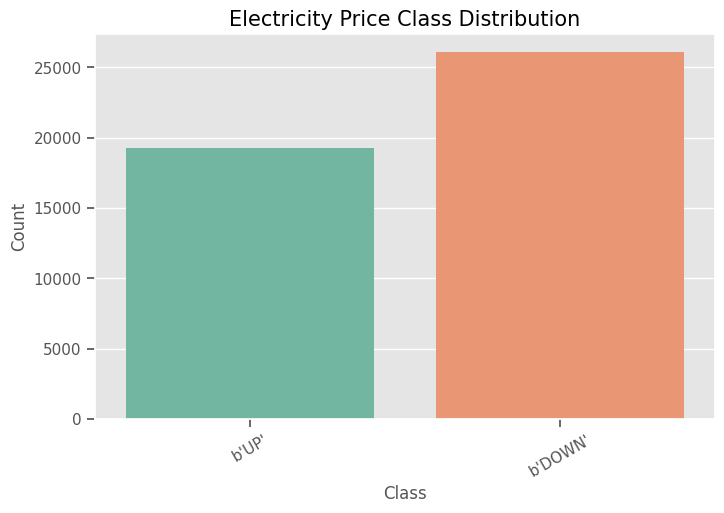

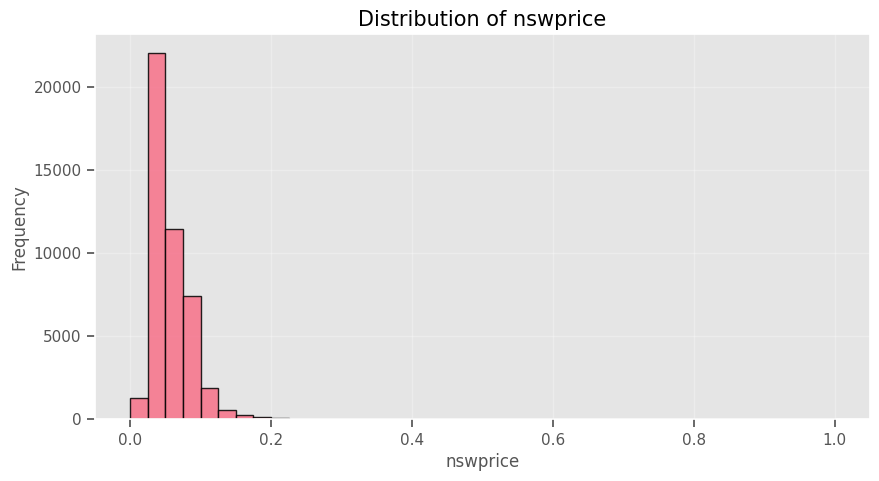

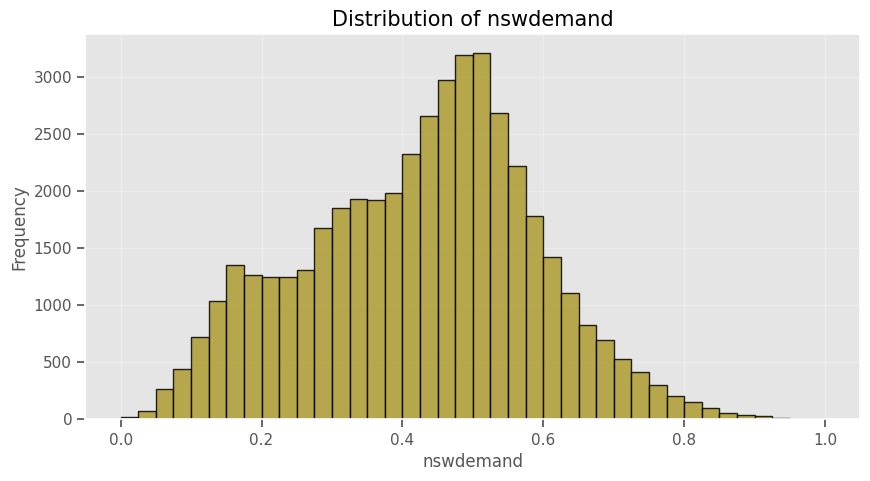

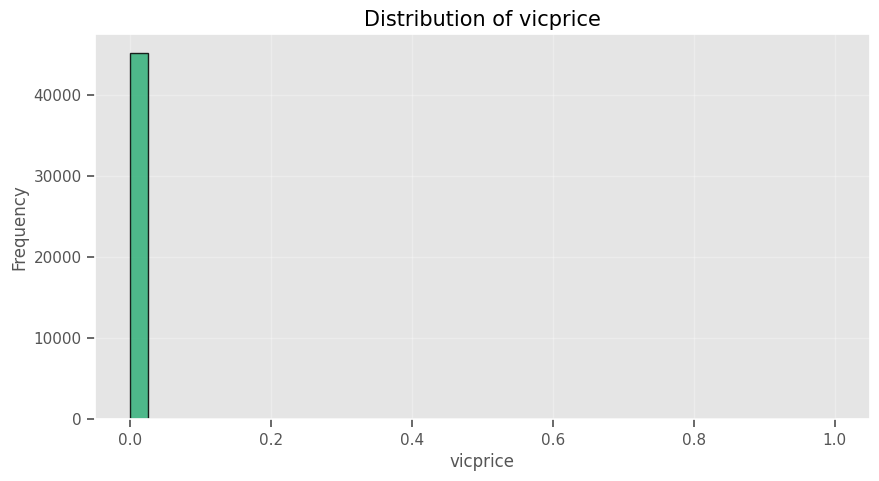

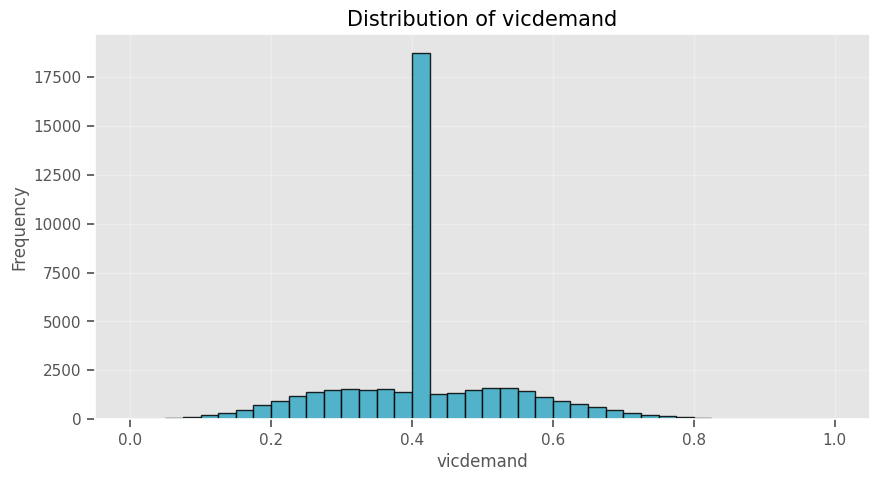

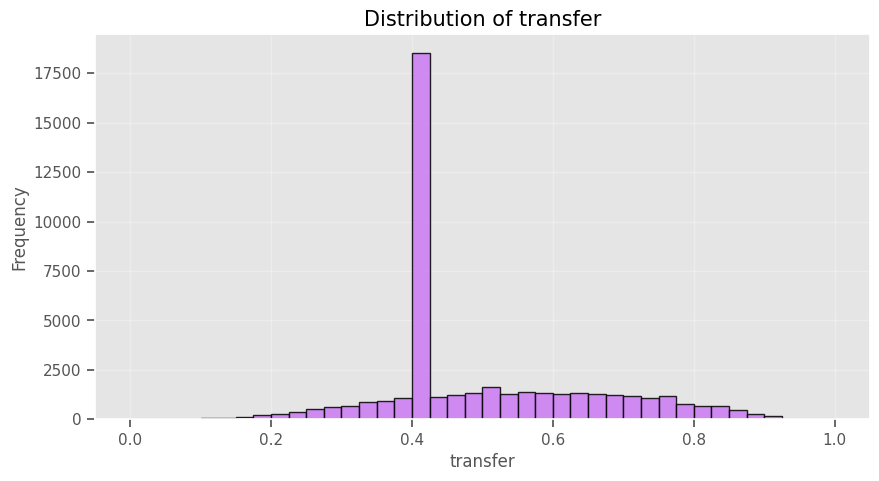

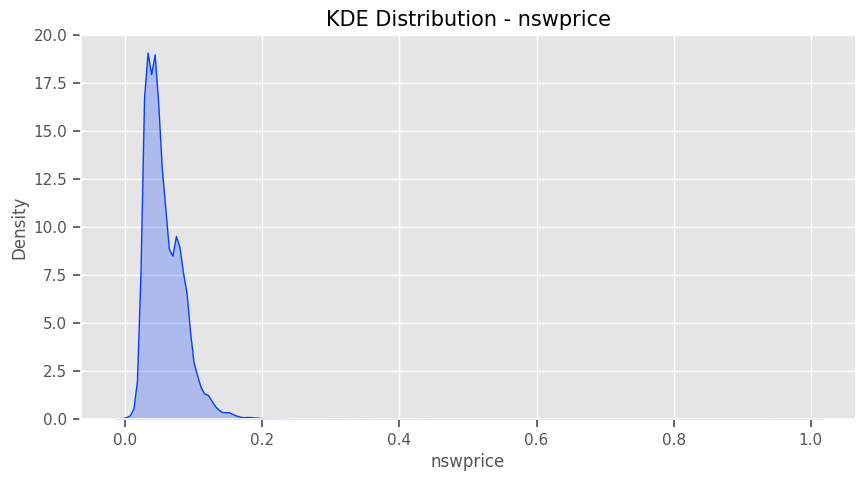

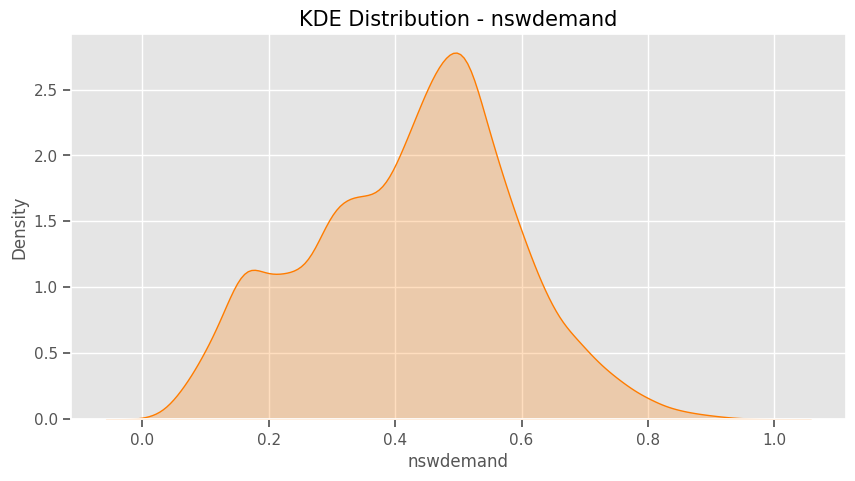

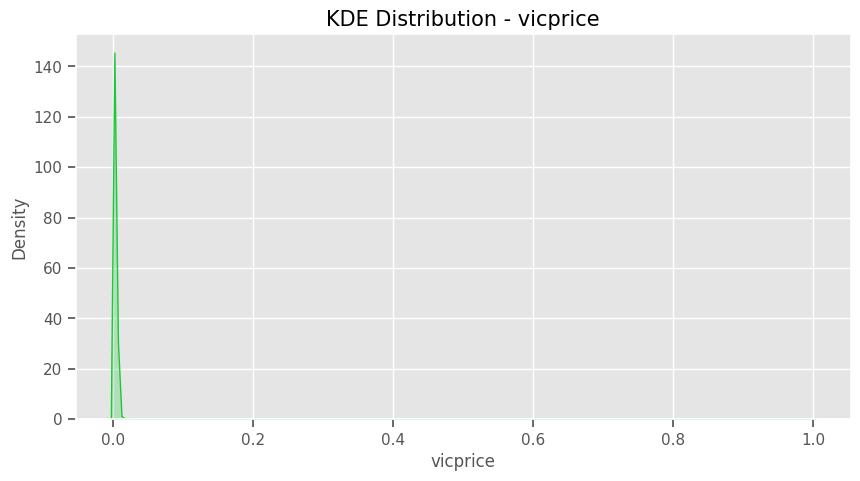

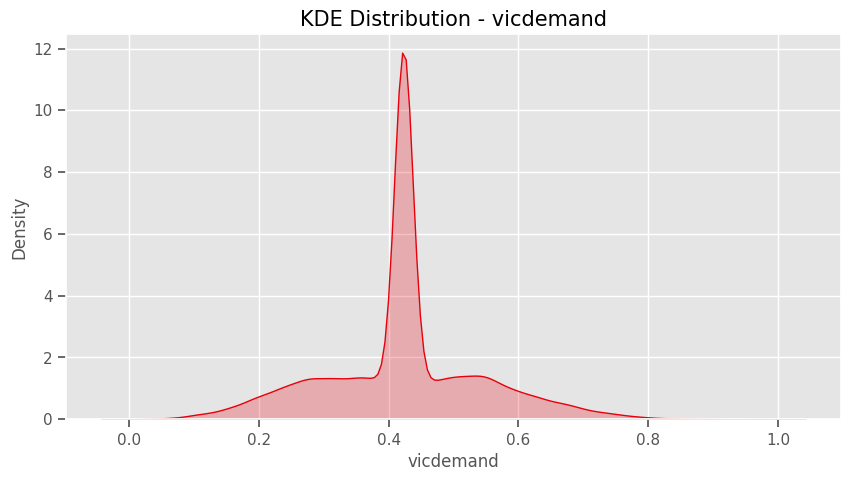

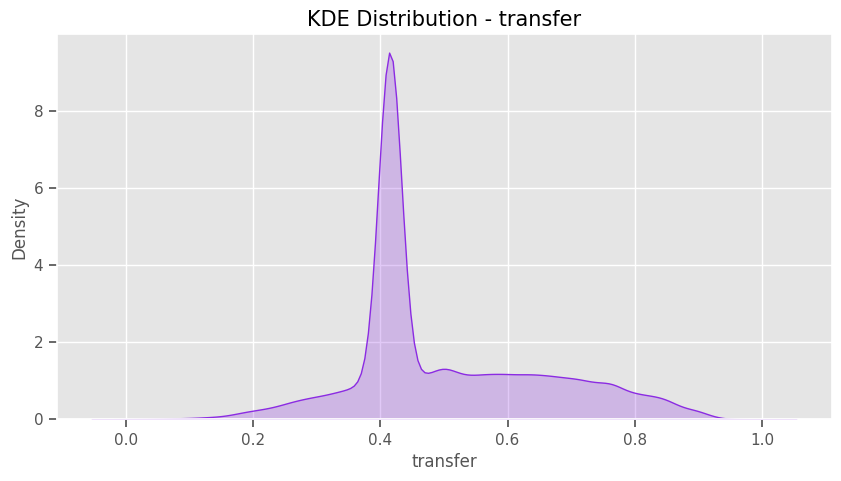

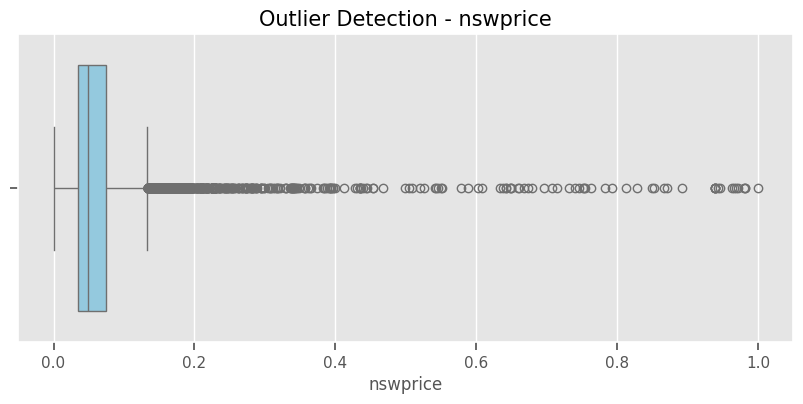

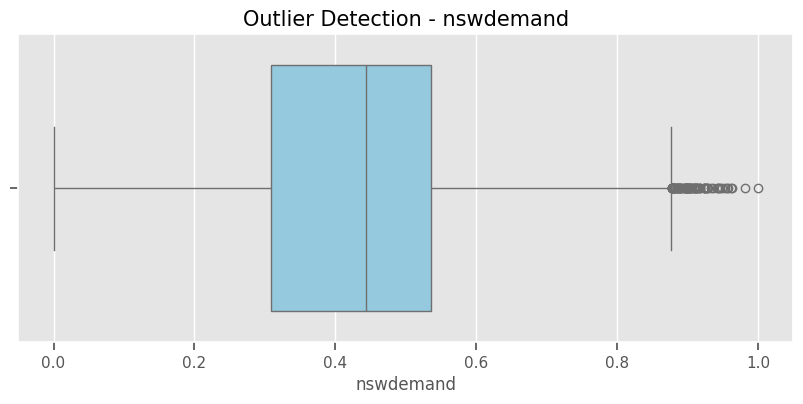

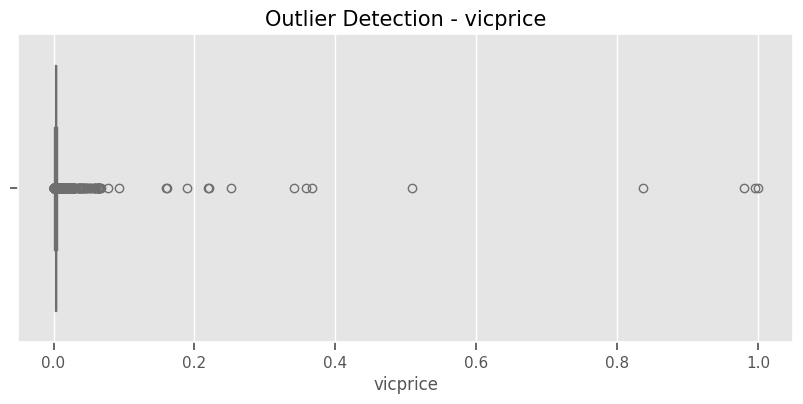

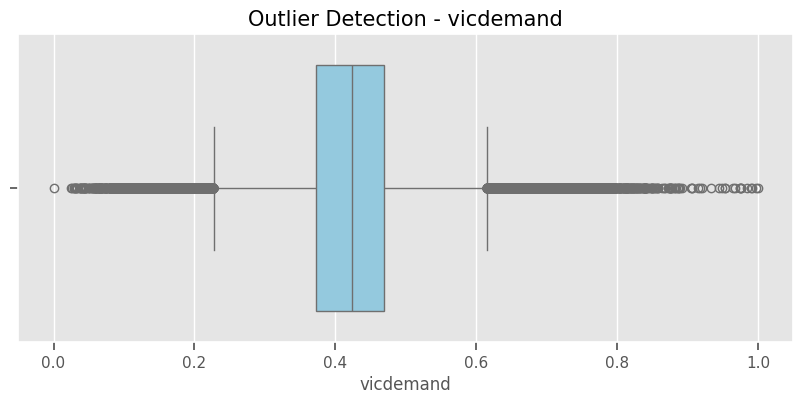

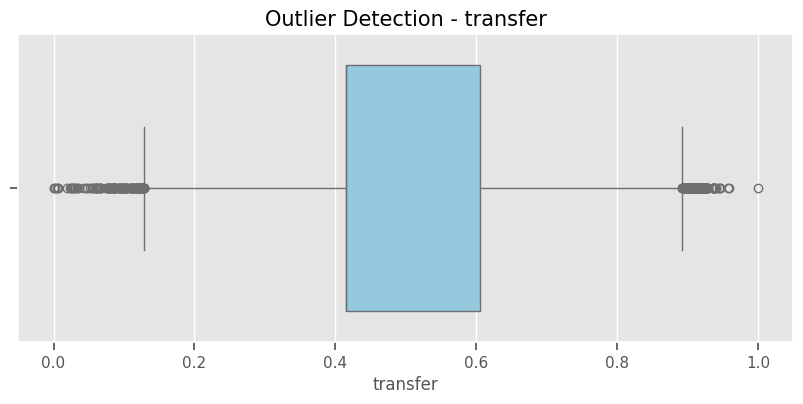

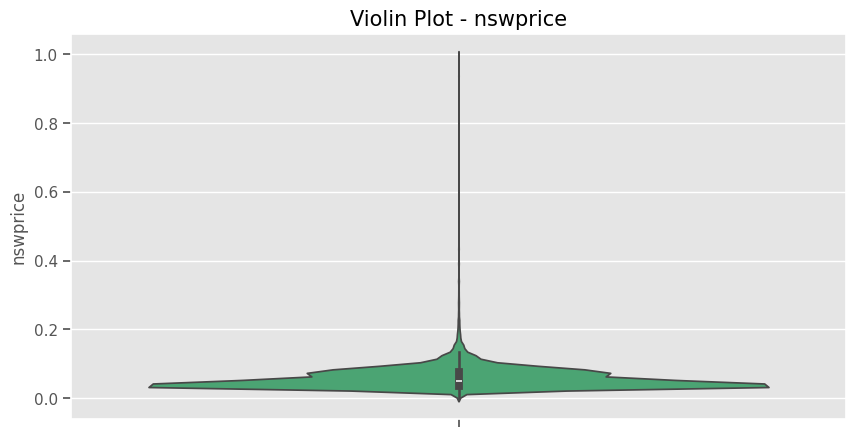

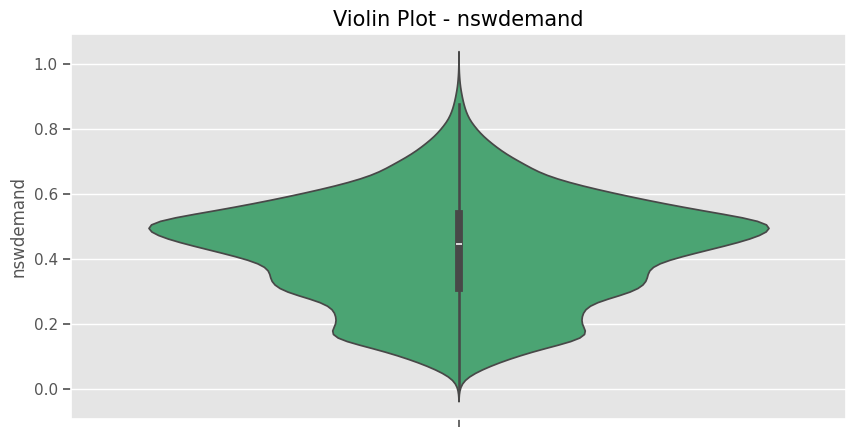

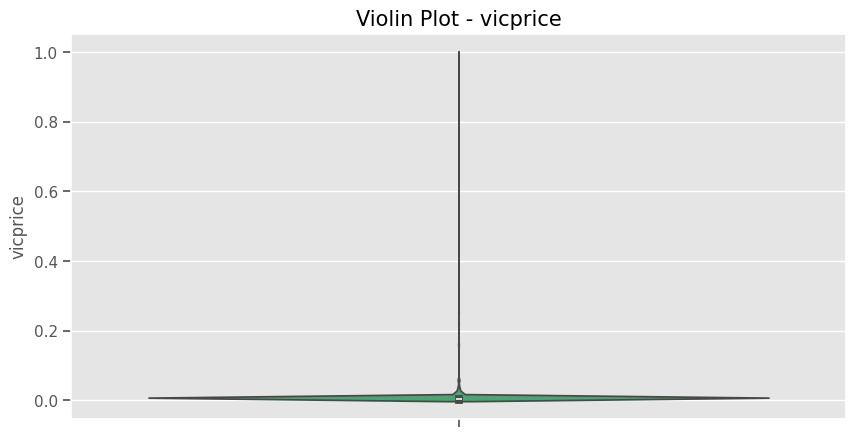

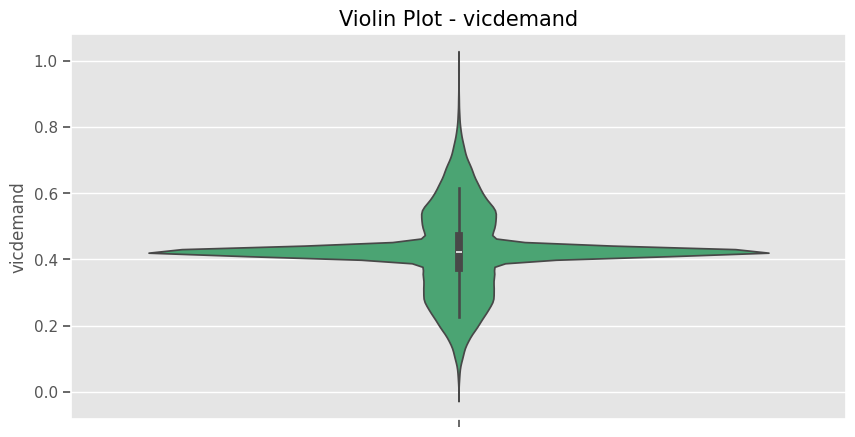

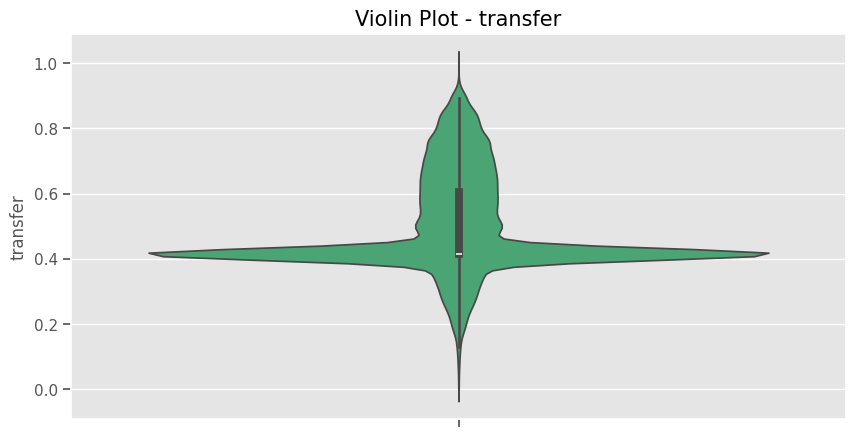

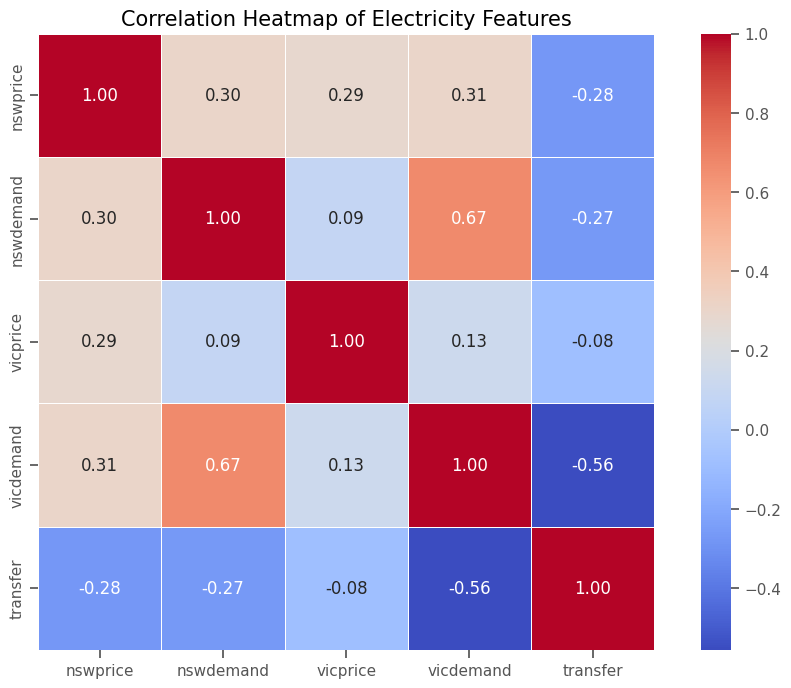

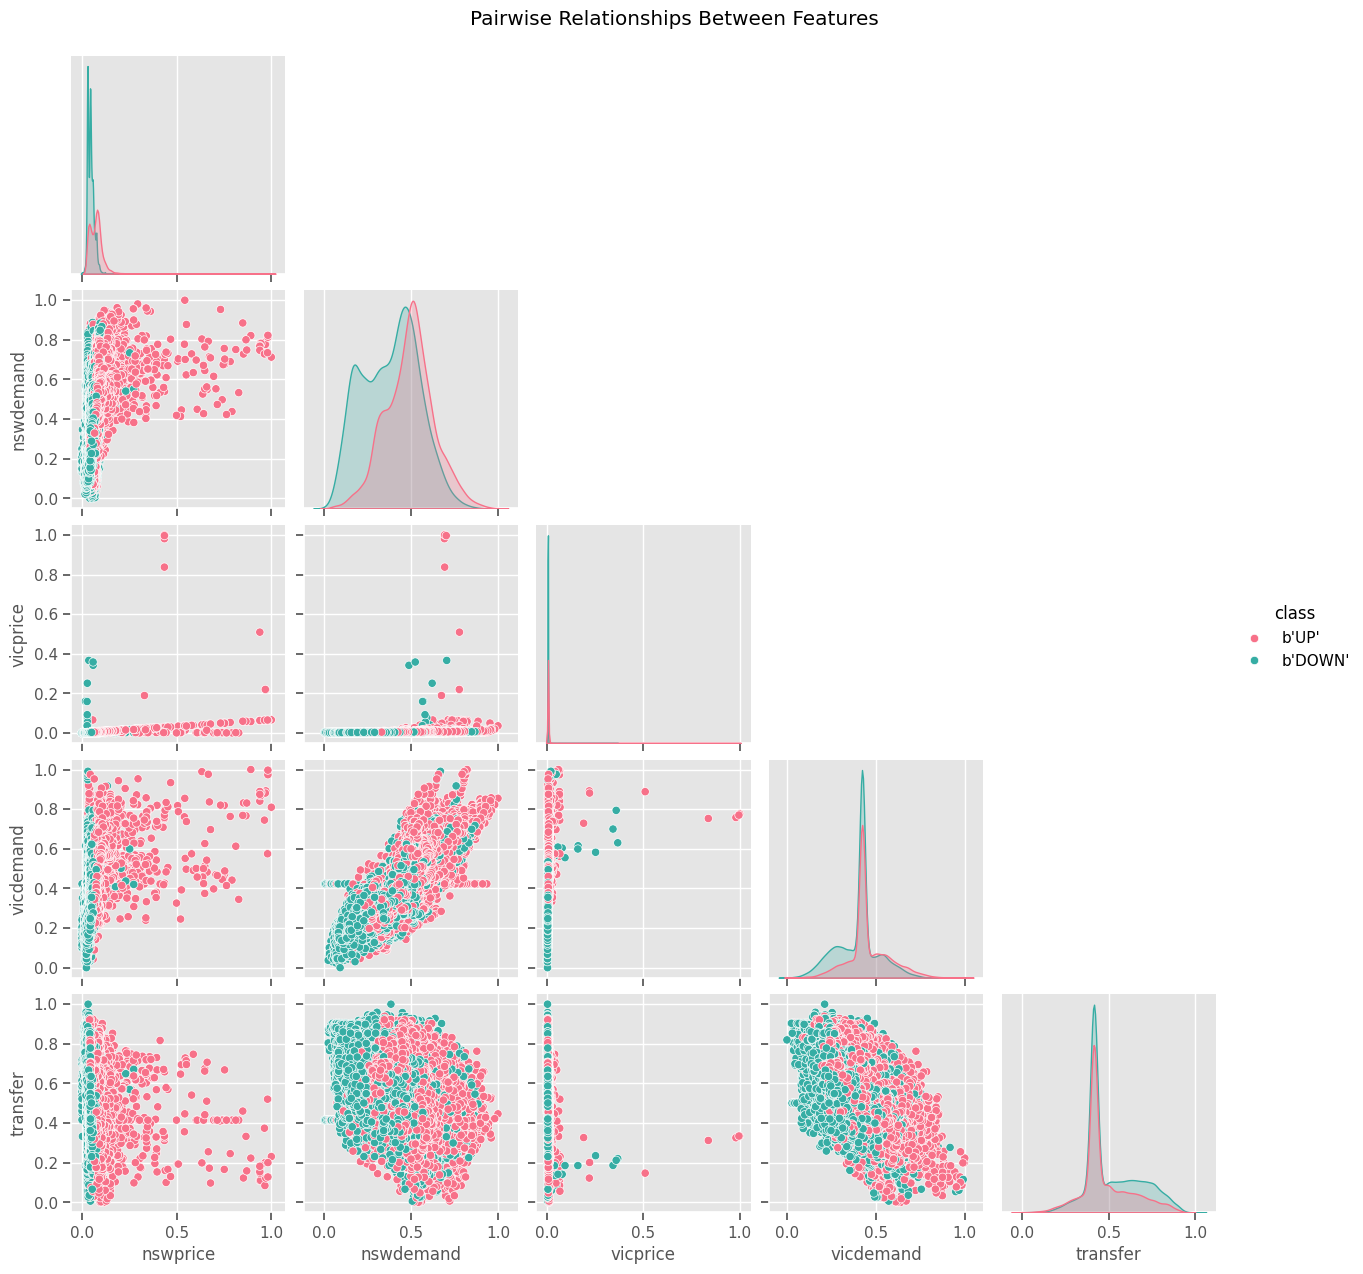

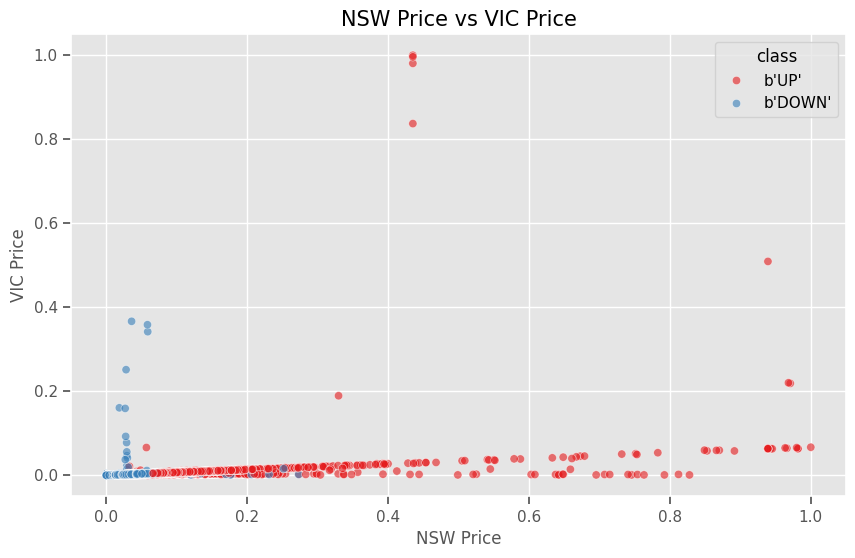

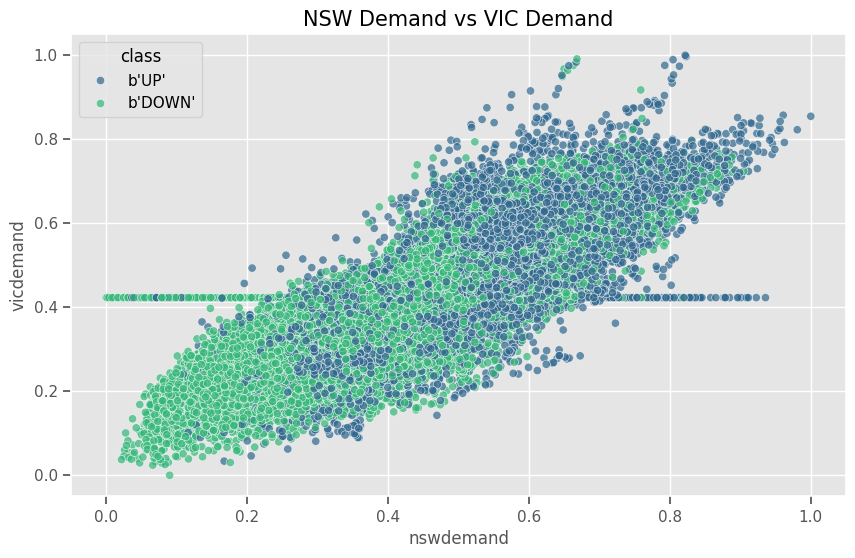

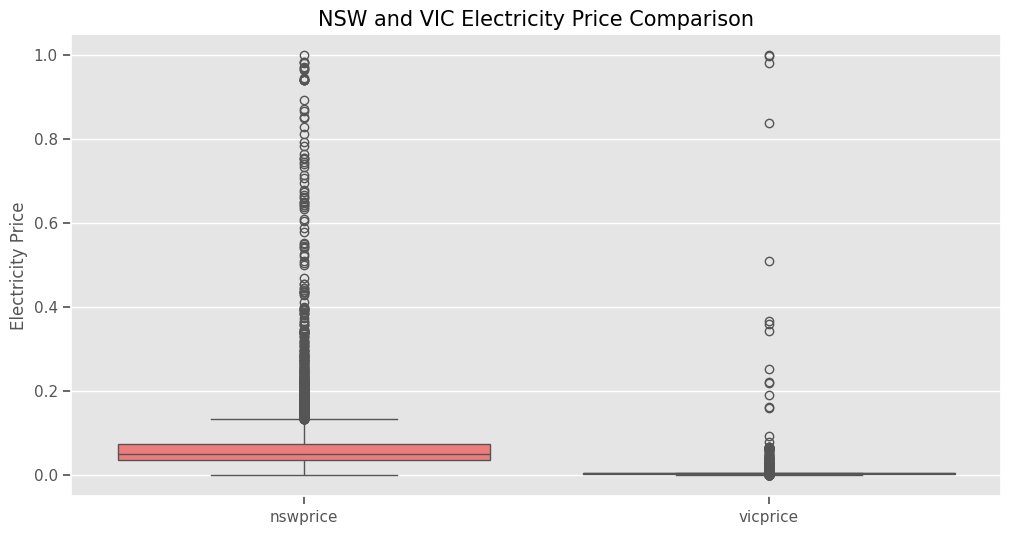

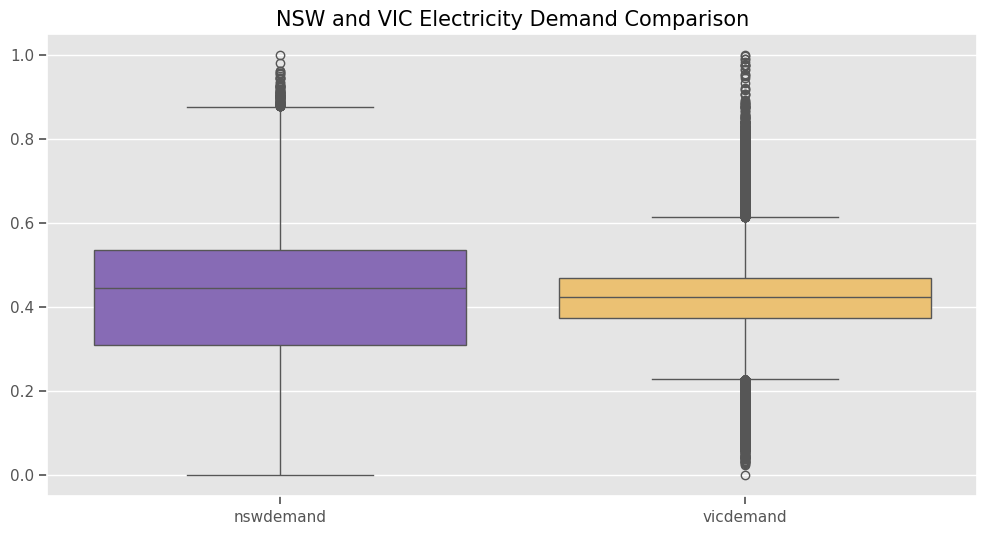

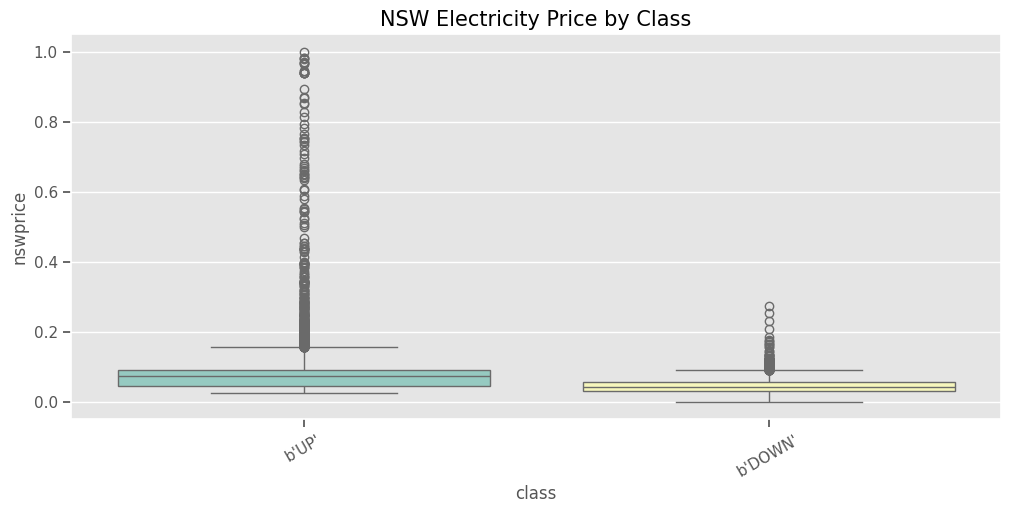

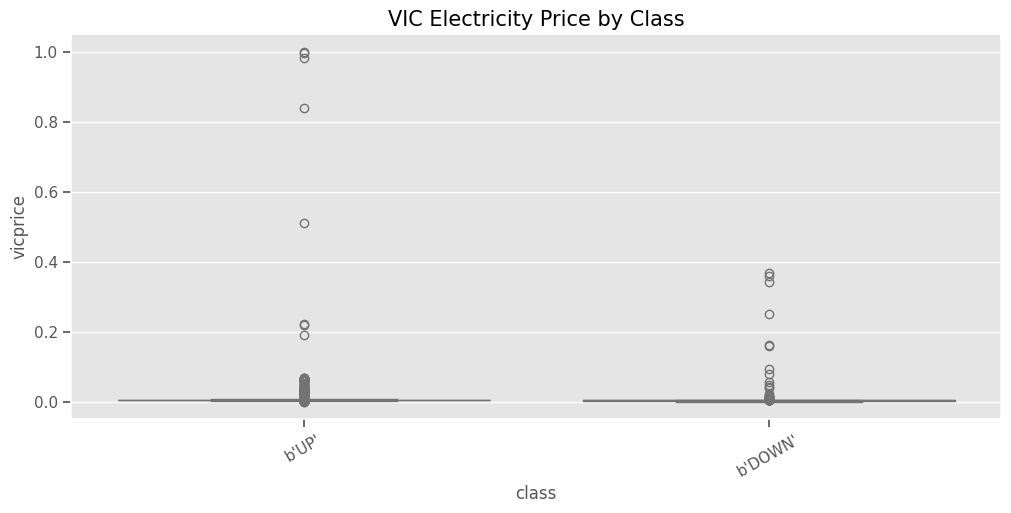

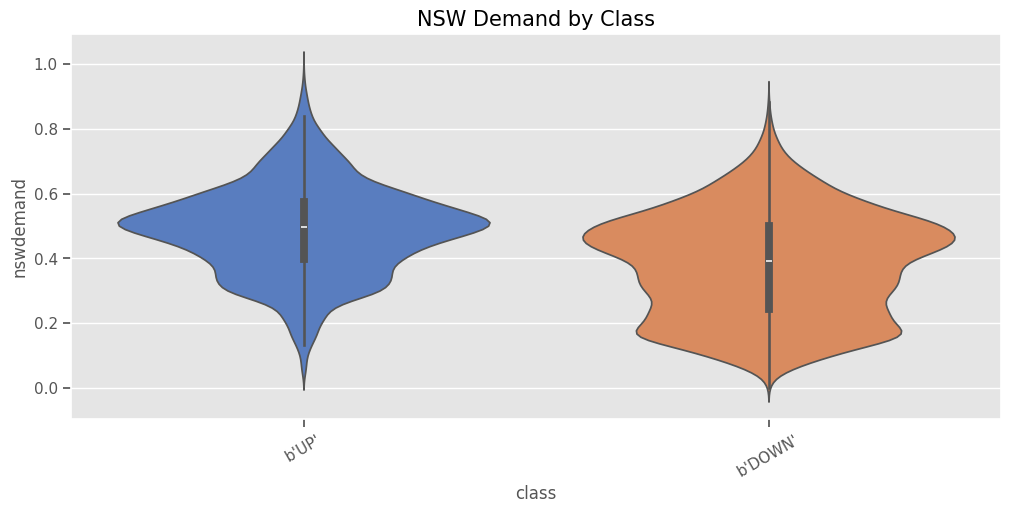

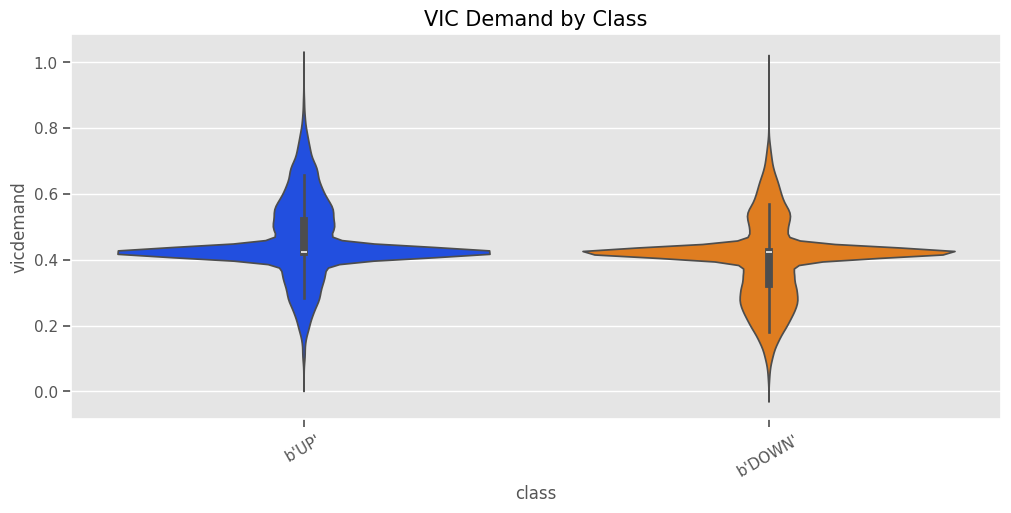

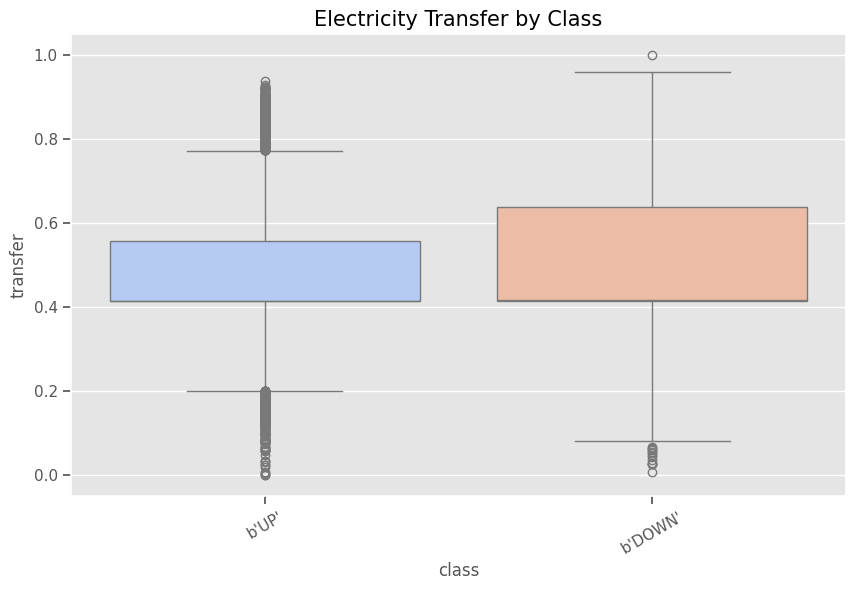

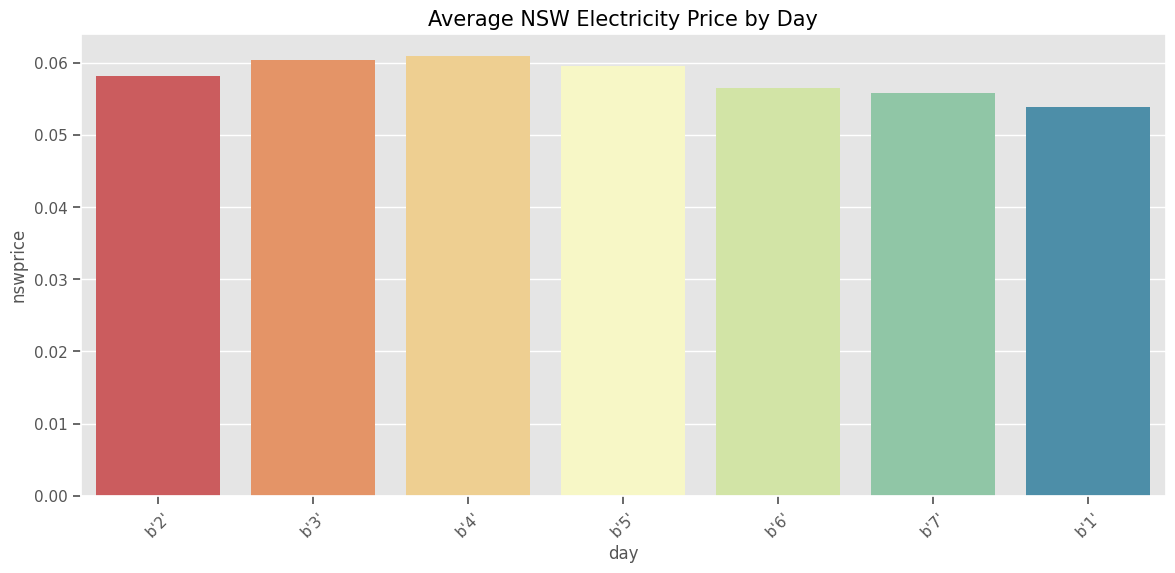

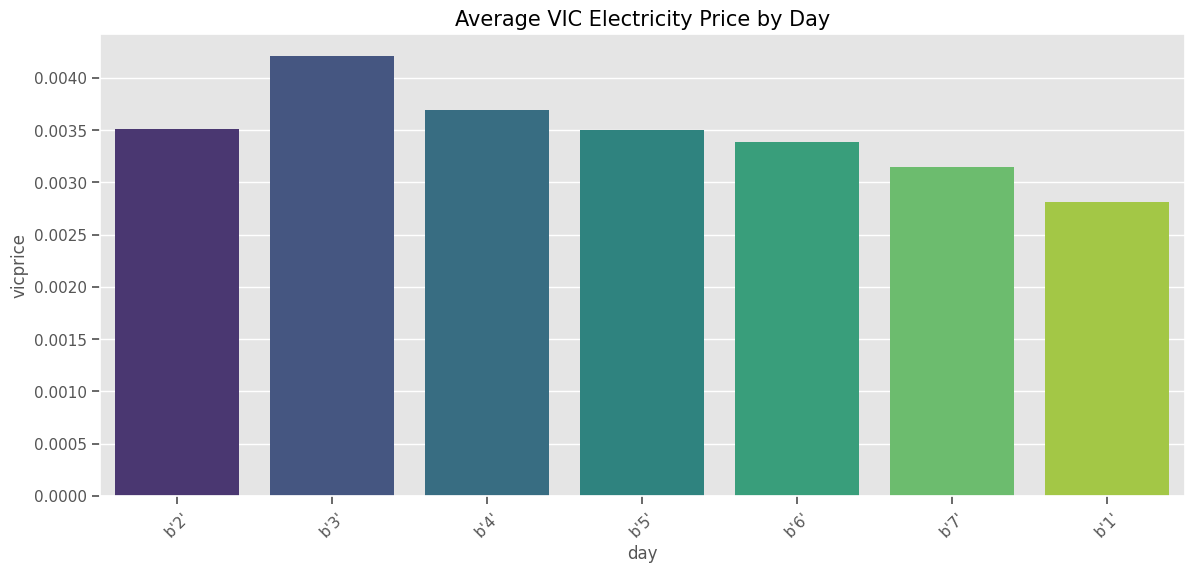

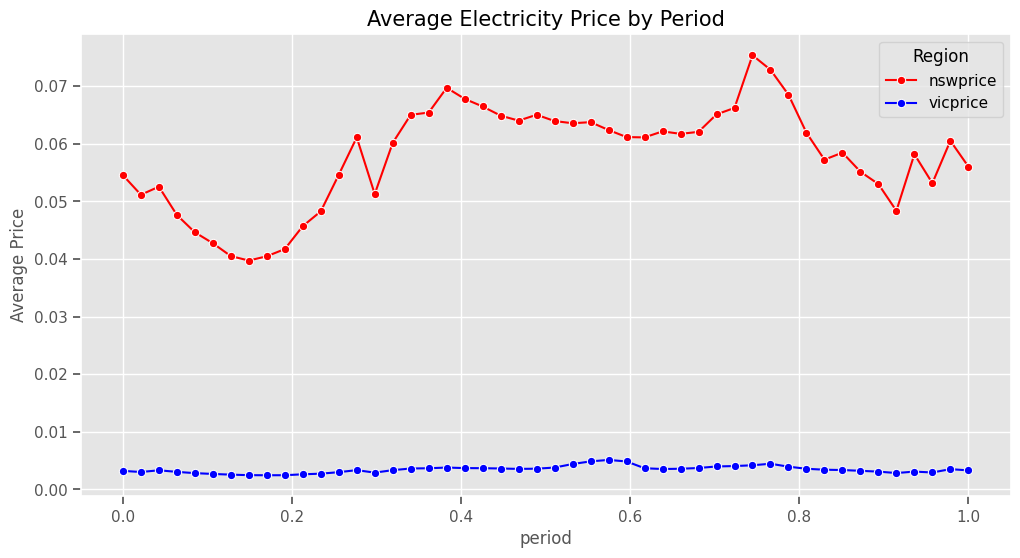

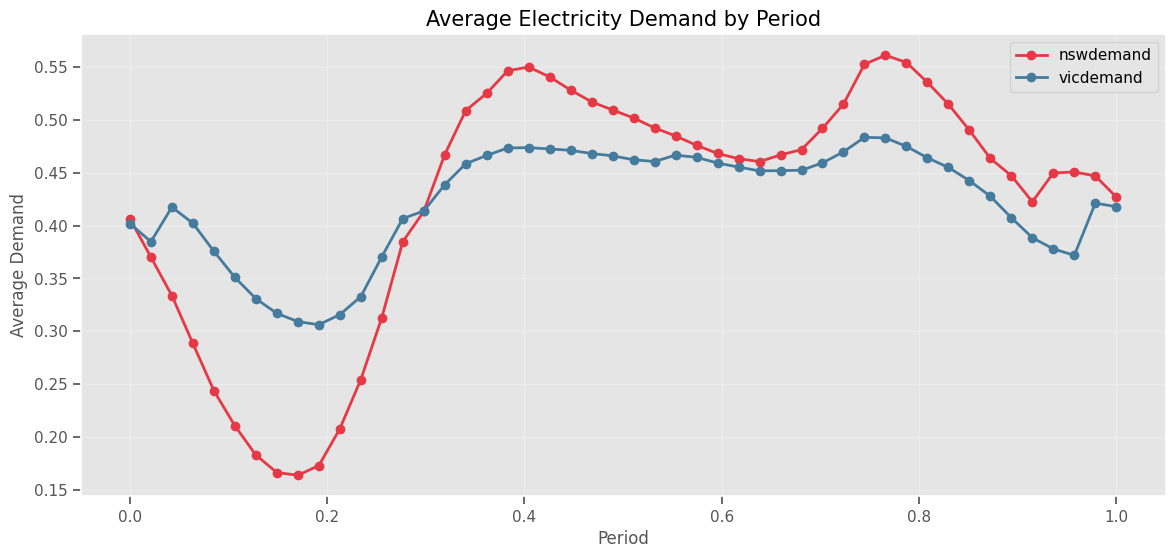

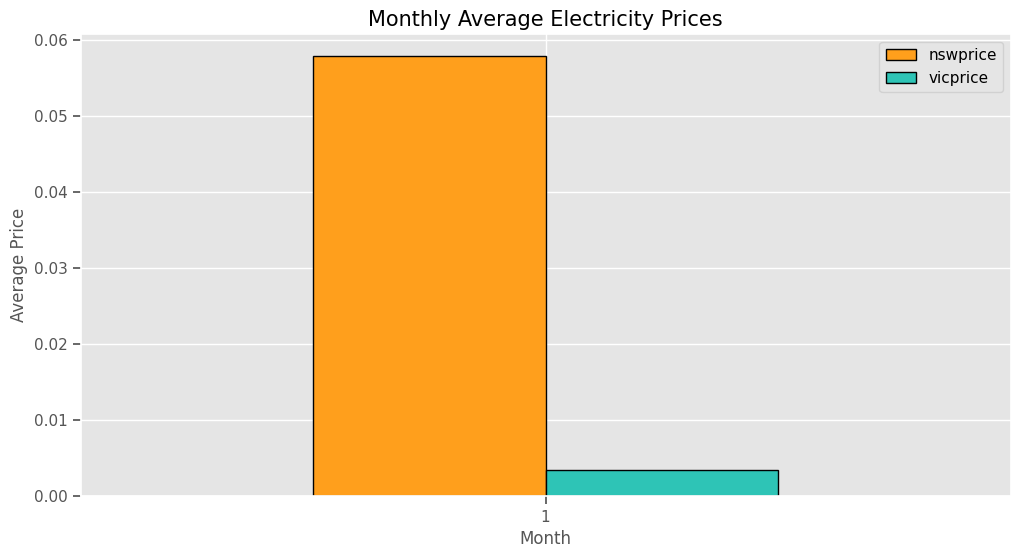

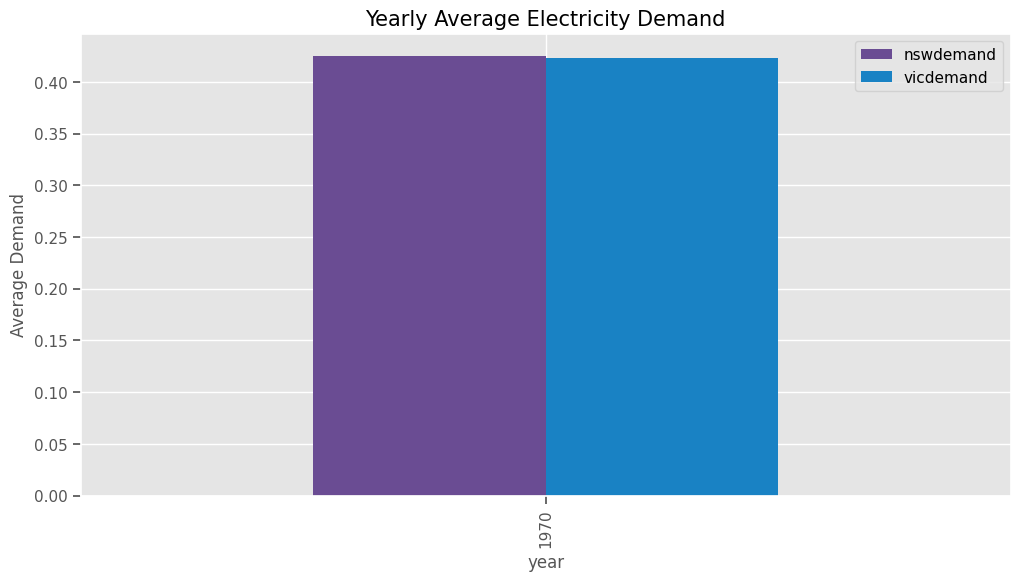

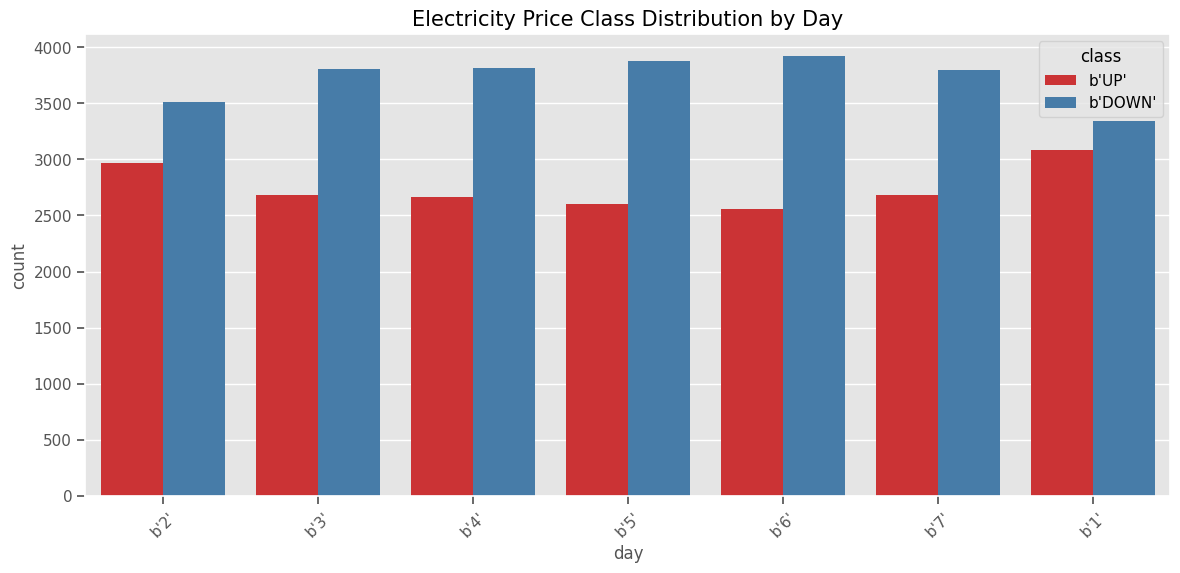

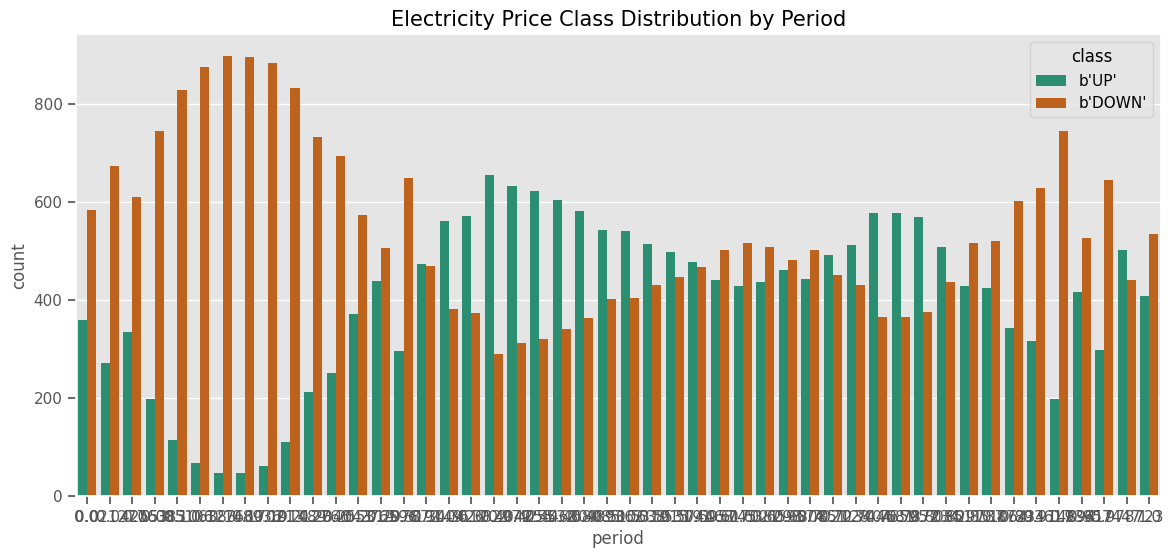

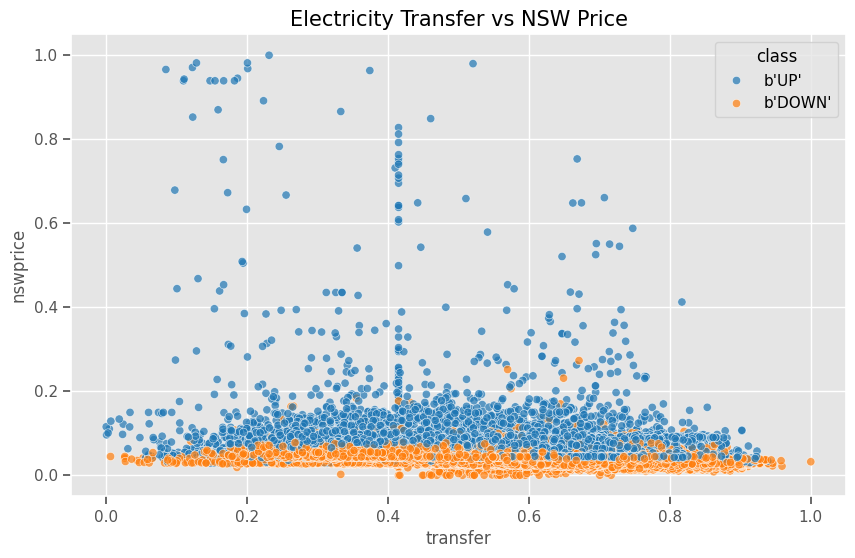

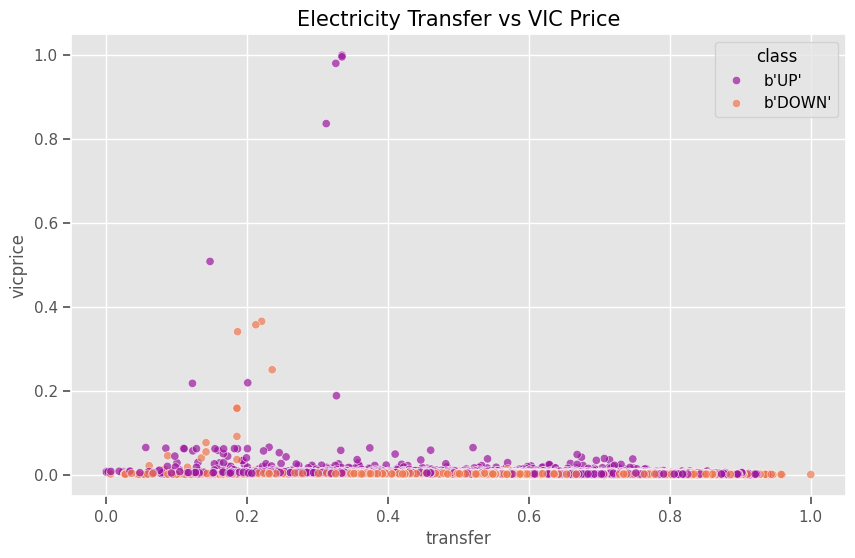

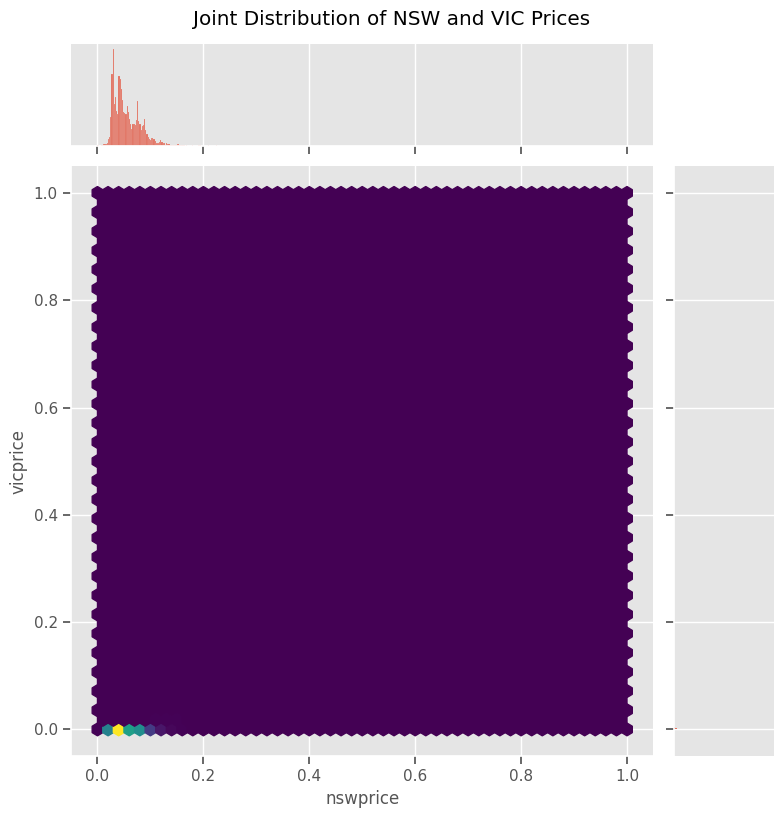

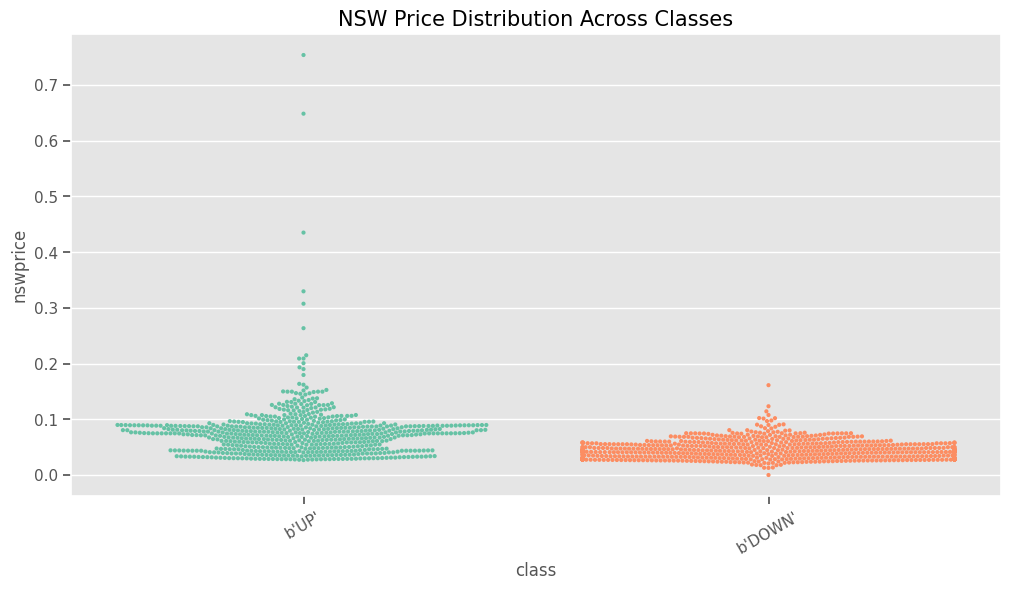

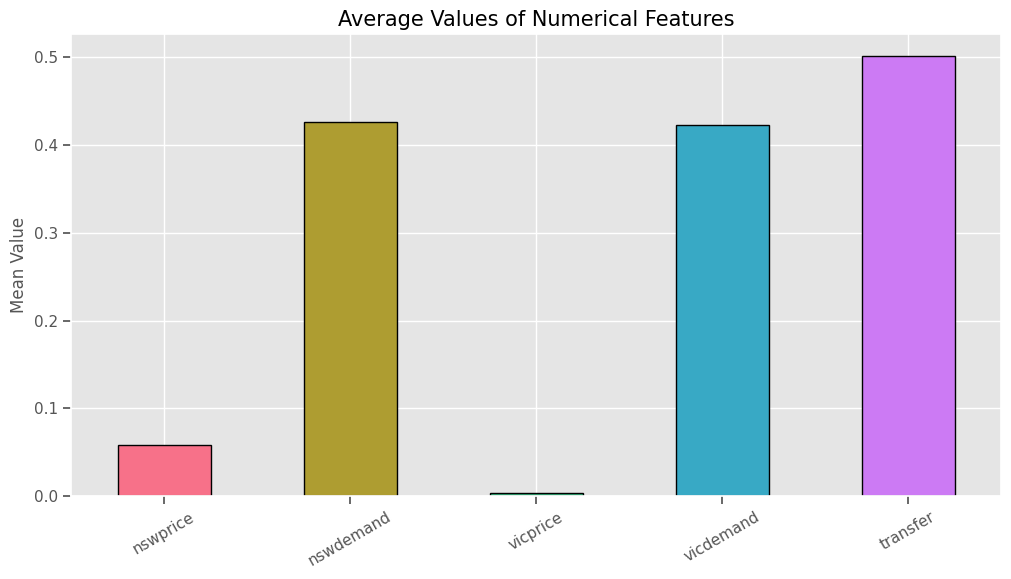

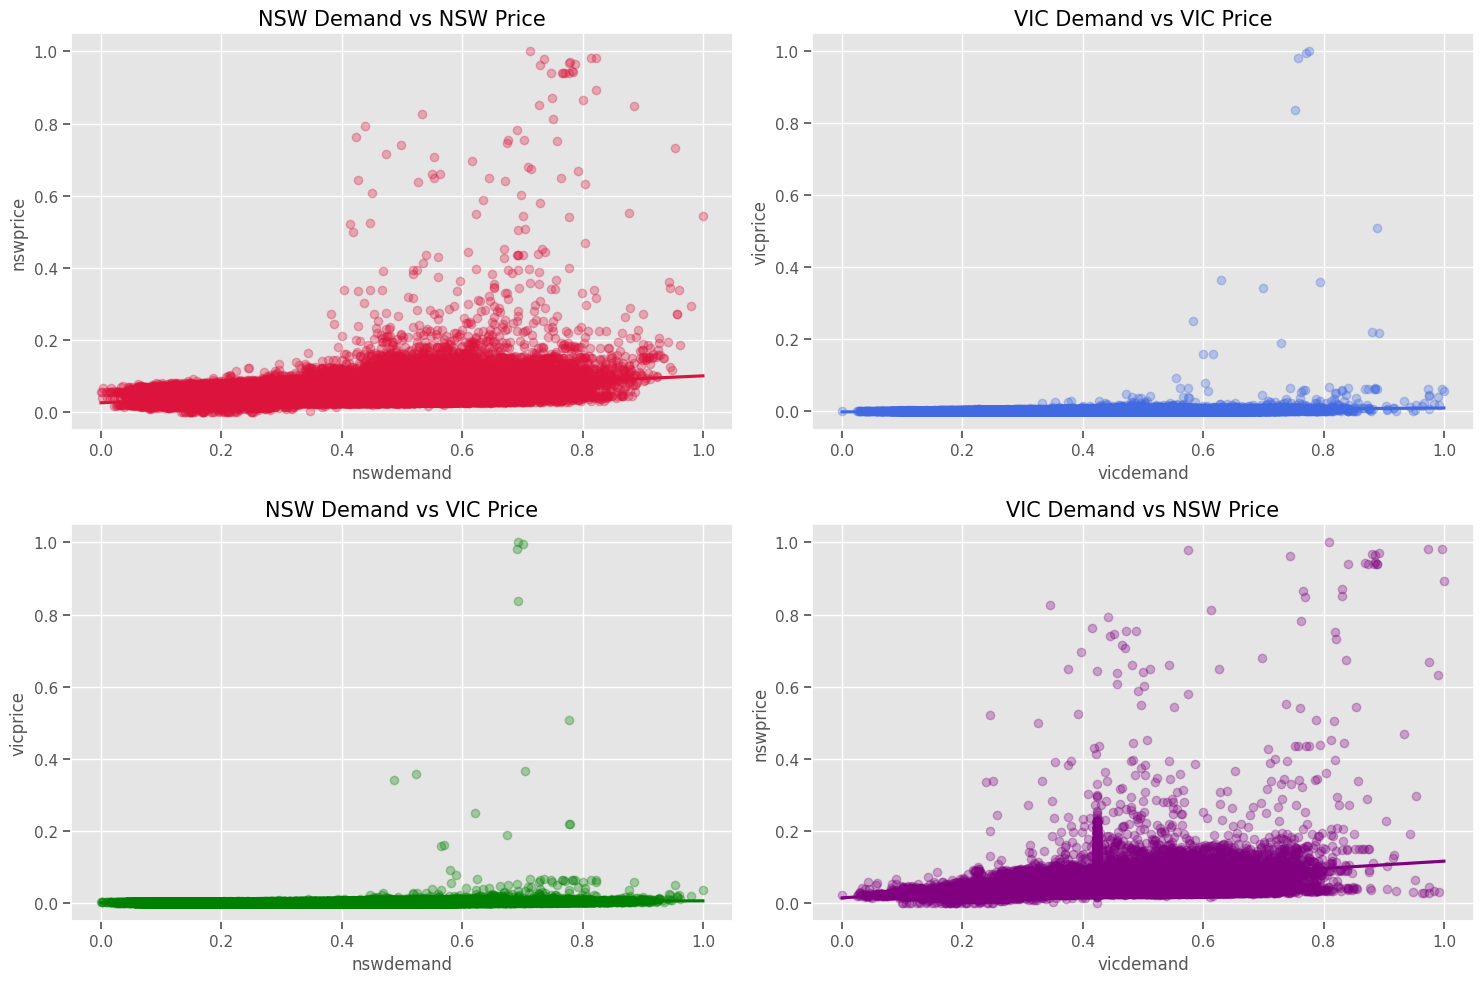


========== FINAL DATASET SUMMARY ==========
Total Rows: 45311
Total Columns: 12

Numerical Feature Statistics:


,nswprice,nswdemand,vicprice,vicdemand,transfer
count,45311.000000,45311.000000,45311.000000,45311.000000,45311.000000
mean,0.057869,0.425424,0.003467,0.422915,0.500528
std,0.039991,0.163320,0.010213,0.120967,0.153375
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.035127,0.309134,0.002277,0.372346,0.414912
50%,0.048667,0.443767,0.003467,0.422915,0.414912
75%,0.074336,0.536001,0.003467,0.469317,0.605702
max,1.000000,1.000000,1.000000,1.000000,1.000000



Class Distribution:


class
b'DOWN'    26074
b'UP'      19237
Name: count, dtype: int64


Average Price:
NSW Average Price: 0.057868672905034085
VIC Average Price: 0.0034670338990532095

Average Demand:
NSW Average Demand: 0.4254235281278277
VIC Average Demand: 0.42291507572112735

========== EDA COMPLETED SUCCESSFULLY ==========


In [11]:
warnings.filterwarnings('ignore')

# Plot settings
plt.style.use('ggplot')
sns.set_context("notebook")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 12

print("FIRST FIVE ROWS")
display(df.head())

print("\nDATASET SHAPE:", df.shape)
print("\nCOLUMN NAMES:")
print(df.columns)

print("\nDATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe())

# ============================================================
# 3. DATA CLEANING
# ============================================================

# Convert date into datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Handle missing numerical values
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nCLEANED DATASET")
print(df.isnull().sum())

# Extract date features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['weekday'] = df['date'].dt.day_name()

# ============================================================
# 4. TARGET DISTRIBUTION
# ============================================================

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='class', hue='class',
              palette='Set2', legend=False)
plt.title('Electricity Price Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 5. HISTOGRAMS - NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    'nswprice', 'nswdemand',
    'vicprice', 'vicdemand', 'transfer'
]

colors = sns.color_palette("husl", len(numeric_cols))

for col, color in zip(numeric_cols, colors):
    plt.figure(figsize=(10,5))
    plt.hist(df[col], bins=40, color=color,
             edgecolor='black', alpha=0.85)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(alpha=0.3)
    plt.show()

# ============================================================
# 6. KDE DISTRIBUTION PLOTS
# ============================================================

for col in numeric_cols:
    plt.figure(figsize=(10,5))
    sns.kdeplot(data=df, x=col, fill=True,
                color=sns.color_palette("bright")[numeric_cols.index(col)])
    plt.title(f'KDE Distribution - {col}')
    plt.xlabel(col)
    plt.show()

# ============================================================
# 7. BOXPLOTS - OUTLIER DETECTION
# ============================================================

for col in numeric_cols:
    plt.figure(figsize=(10,4))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Outlier Detection - {col}')
    plt.xlabel(col)
    plt.show()

# ============================================================
# 8. VIOLIN PLOTS
# ============================================================

for col in numeric_cols:
    plt.figure(figsize=(10,5))
    sns.violinplot(y=df[col], color='mediumseagreen')
    plt.title(f'Violin Plot - {col}')
    plt.show()

# ============================================================
# 9. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(12,8))

correlation = df[numeric_cols].corr()

sns.heatmap(correlation, annot=True,
            cmap='coolwarm', fmt='.2f',
            linewidths=0.5, square=True)

plt.title('Correlation Heatmap of Electricity Features')
plt.show()

# ============================================================
# 10. PAIR PLOT
# ============================================================

sns.pairplot(
    df[numeric_cols + ['class']],
    hue='class',
    palette='husl',
    diag_kind='kde',
    corner=True
)
plt.suptitle('Pairwise Relationships Between Features', y=1.02)
plt.show()

# ============================================================
# 11. NSW VS VIC PRICE COMPARISON
# ============================================================

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='nswprice',
    y='vicprice',
    hue='class',
    palette='Set1',
    alpha=0.6
)

plt.title('NSW Price vs VIC Price')
plt.xlabel('NSW Price')
plt.ylabel('VIC Price')
plt.show()

# ============================================================
# 12. NSW VS VIC DEMAND COMPARISON
# ============================================================

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='nswdemand',
    y='vicdemand',
    hue='class',
    palette='viridis',
    alpha=0.7
)

plt.title('NSW Demand vs VIC Demand')
plt.show()

# ============================================================
# 13. ELECTRICITY PRICE COMPARISON
# ============================================================

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[['nswprice','vicprice']],
    palette=['#FF6B6B','#4ECDC4']
)

plt.title('NSW and VIC Electricity Price Comparison')
plt.ylabel('Electricity Price')
plt.show()

# ============================================================
# 14. ELECTRICITY DEMAND COMPARISON
# ============================================================

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[['nswdemand','vicdemand']],
    palette=['#845EC2','#FFC75F']
)

plt.title('NSW and VIC Electricity Demand Comparison')
plt.show()

# ============================================================
# 15. CLASS-WISE ELECTRICITY PRICE
# ============================================================

plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x='class',
    y='nswprice',
    hue='class',
    palette='Set3',
    legend=False
)

plt.title('NSW Electricity Price by Class')
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x='class',
    y='vicprice',
    hue='class',
    palette='pastel',
    legend=False
)

plt.title('VIC Electricity Price by Class')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 16. CLASS-WISE DEMAND
# ============================================================

plt.figure(figsize=(12,5))

sns.violinplot(
    data=df,
    x='class',
    y='nswdemand',
    hue='class',
    palette='muted',
    legend=False
)

plt.title('NSW Demand by Class')
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(12,5))

sns.violinplot(
    data=df,
    x='class',
    y='vicdemand',
    hue='class',
    palette='bright',
    legend=False
)

plt.title('VIC Demand by Class')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 17. TRANSFER DISTRIBUTION BY CLASS
# ============================================================

plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x='class',
    y='transfer',
    hue='class',
    palette='coolwarm',
    legend=False
)

plt.title('Electricity Transfer by Class')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 18. DAY-WISE PRICE ANALYSIS
# ============================================================

plt.figure(figsize=(14,6))

sns.barplot(
    data=df,
    x='day',
    y='nswprice',
    hue='day',
    palette='Spectral',
    errorbar=None,
    legend=False
)

plt.title('Average NSW Electricity Price by Day')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(14,6))

sns.barplot(
    data=df,
    x='day',
    y='vicprice',
    hue='day',
    palette='viridis',
    errorbar=None,
    legend=False
)

plt.title('Average VIC Electricity Price by Day')
plt.xticks(rotation=45)
plt.show()

# ============================================================
# 19. PERIOD-WISE PRICE ANALYSIS
# ============================================================

plt.figure(figsize=(12,6))

sns.lineplot(
    data=df.groupby('period', as_index=False)[
        ['nswprice','vicprice']
    ].mean().melt(
        id_vars='period',
        var_name='Region',
        value_name='Average Price'
    ),
    x='period',
    y='Average Price',
    hue='Region',
    palette=['red','blue'],
    marker='o'
)

plt.title('Average Electricity Price by Period')
plt.show()

# ============================================================
# 20. PERIOD-WISE DEMAND ANALYSIS
# ============================================================

period_demand = df.groupby('period')[
    ['nswdemand','vicdemand']
].mean()

period_demand.plot(
    kind='line',
    figsize=(14,6),
    color=['#E63946','#457B9D'],
    marker='o',
    linewidth=2
)

plt.title('Average Electricity Demand by Period')
plt.xlabel('Period')
plt.ylabel('Average Demand')
plt.grid(alpha=0.3)
plt.show()

# ============================================================
# 21. MONTH-WISE PRICE ANALYSIS
# ============================================================

monthly_price = df.groupby('month')[
    ['nswprice','vicprice']
].mean()

monthly_price.plot(
    kind='bar',
    figsize=(12,6),
    color=['#FF9F1C','#2EC4B6'],
    edgecolor='black'
)

plt.title('Monthly Average Electricity Prices')
plt.xlabel('Month')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.show()

# ============================================================
# 22. YEAR-WISE DEMAND ANALYSIS
# ============================================================

if df['year'].notna().any():

    yearly_demand = df.groupby('year')[
        ['nswdemand','vicdemand']
    ].mean()

    yearly_demand.plot(
        kind='bar',
        figsize=(12,6),
        color=['#6A4C93','#1982C4']
    )

    plt.title('Yearly Average Electricity Demand')
    plt.ylabel('Average Demand')
    plt.show()

# ============================================================
# 23. DAY-WISE CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(14,6))

sns.countplot(
    data=df,
    x='day',
    hue='class',
    palette='Set1'
)

plt.title('Electricity Price Class Distribution by Day')
plt.xticks(rotation=45)
plt.show()

# ============================================================
# 24. PERIOD-WISE CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(14,6))

sns.countplot(
    data=df,
    x='period',
    hue='class',
    palette='Dark2'
)

plt.title('Electricity Price Class Distribution by Period')
plt.show()

# ============================================================
# 25. SCATTER PLOT - TRANSFER VS PRICE
# ============================================================

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='transfer',
    y='nswprice',
    hue='class',
    palette='tab10',
    alpha=0.7
)

plt.title('Electricity Transfer vs NSW Price')
plt.show()

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='transfer',
    y='vicprice',
    hue='class',
    palette='plasma',
    alpha=0.7
)

plt.title('Electricity Transfer vs VIC Price')
plt.show()

# ============================================================
# 26. JOINT DISTRIBUTION
# ============================================================

sns.jointplot(
    data=df,
    x='nswprice',
    y='vicprice',
    kind='hex',
    cmap='viridis',
    height=8
)

plt.suptitle('Joint Distribution of NSW and VIC Prices', y=1.02)
plt.show()

# ============================================================
# 27. SWARM PLOT (SAMPLE FOR LARGE DATASETS)
# ============================================================

sample_df = df.sample(min(1500, len(df)), random_state=42)

plt.figure(figsize=(12,6))

sns.swarmplot(
    data=sample_df,
    x='class',
    y='nswprice',
    hue='class',
    palette='Set2',
    legend=False,
    size=3
)

plt.title('NSW Price Distribution Across Classes')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 28. FEATURE-WISE MEAN COMPARISON
# ============================================================

mean_values = df[numeric_cols].mean()

plt.figure(figsize=(12,6))

mean_values.plot(
    kind='bar',
    color=sns.color_palette('husl', len(numeric_cols)),
    edgecolor='black'
)

plt.title('Average Values of Numerical Features')
plt.ylabel('Mean Value')
plt.xticks(rotation=30)
plt.show()

# ============================================================
# 29. PAIRWISE PRICE AND DEMAND TRENDS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15,10))

sns.regplot(data=df, x='nswdemand', y='nswprice',
            ax=axes[0,0], color='crimson',
            scatter_kws={'alpha':0.3})

sns.regplot(data=df, x='vicdemand', y='vicprice',
            ax=axes[0,1], color='royalblue',
            scatter_kws={'alpha':0.3})

sns.regplot(data=df, x='nswdemand', y='vicprice',
            ax=axes[1,0], color='green',
            scatter_kws={'alpha':0.3})

sns.regplot(data=df, x='vicdemand', y='nswprice',
            ax=axes[1,1], color='purple',
            scatter_kws={'alpha':0.3})

axes[0,0].set_title('NSW Demand vs NSW Price')
axes[0,1].set_title('VIC Demand vs VIC Price')
axes[1,0].set_title('NSW Demand vs VIC Price')
axes[1,1].set_title('VIC Demand vs NSW Price')

plt.tight_layout()
plt.show()

# ============================================================
# 30. FINAL SUMMARY
# ============================================================

print("\n========== FINAL DATASET SUMMARY ==========")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nNumerical Feature Statistics:")
display(df[numeric_cols].describe())

print("\nClass Distribution:")
display(df['class'].value_counts())

print("\nAverage Price:")
print("NSW Average Price:", df['nswprice'].mean())
print("VIC Average Price:", df['vicprice'].mean())

print("\nAverage Demand:")
print("NSW Average Demand:", df['nswdemand'].mean())
print("VIC Average Demand:", df['vicdemand'].mean())

print("\n========== EDA COMPLETED SUCCESSFULLY ==========")


## Feature engineering

DATASET SHAPE: (45311, 12)

FIRST FIVE RECORDS


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class,year,month,weekday
0,1970-01-01,b'2',0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,b'UP',1970,1,Thursday
1,1970-01-01,b'2',0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,b'UP',1970,1,Thursday
2,1970-01-01,b'2',0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,b'UP',1970,1,Thursday
3,1970-01-01,b'2',0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,b'UP',1970,1,Thursday
4,1970-01-01,b'2',0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,b'DOWN',1970,1,Thursday



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 45311 entries, 0 to 45311
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       45311 non-null  datetime64[ns]
 1   day        45311 non-null  object        
 2   period     45311 non-null  float64       
 3   nswprice   45311 non-null  float64       
 4   nswdemand  45311 non-null  float64       
 5   vicprice   45311 non-null  float64       
 6   vicdemand  45311 non-null  float64       
 7   transfer   45311 non-null  float64       
 8   class      45311 non-null  object        
 9   year       45311 non-null  int32         
 10  month      45311 non-null  int32         
 11  weekday    45311 non-null  object        
dtypes: datetime64[ns](1), float64(6), int32(2), object(3)
memory usage: 5.2+ MB

FEATURE COLUMNS:
['day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer', 'year', 'month', 'weekday', 'day_of_mo

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,85.85,85.84,85.85,85.79
1,Extra Trees,84.59,84.55,84.59,84.52
2,Hist Gradient Boosting,82.36,82.31,82.36,82.26
3,KNN,82.19,82.13,82.19,82.13
4,Decision Tree,80.73,80.69,80.73,80.59
5,Gradient Boosting,79.61,79.69,79.61,79.33
6,SVM,78.30,78.61,78.30,77.82
7,Logistic Regression,75.80,76.00,75.80,75.25
8,Gaussian Naive Bayes,72.88,77.42,72.88,70.15


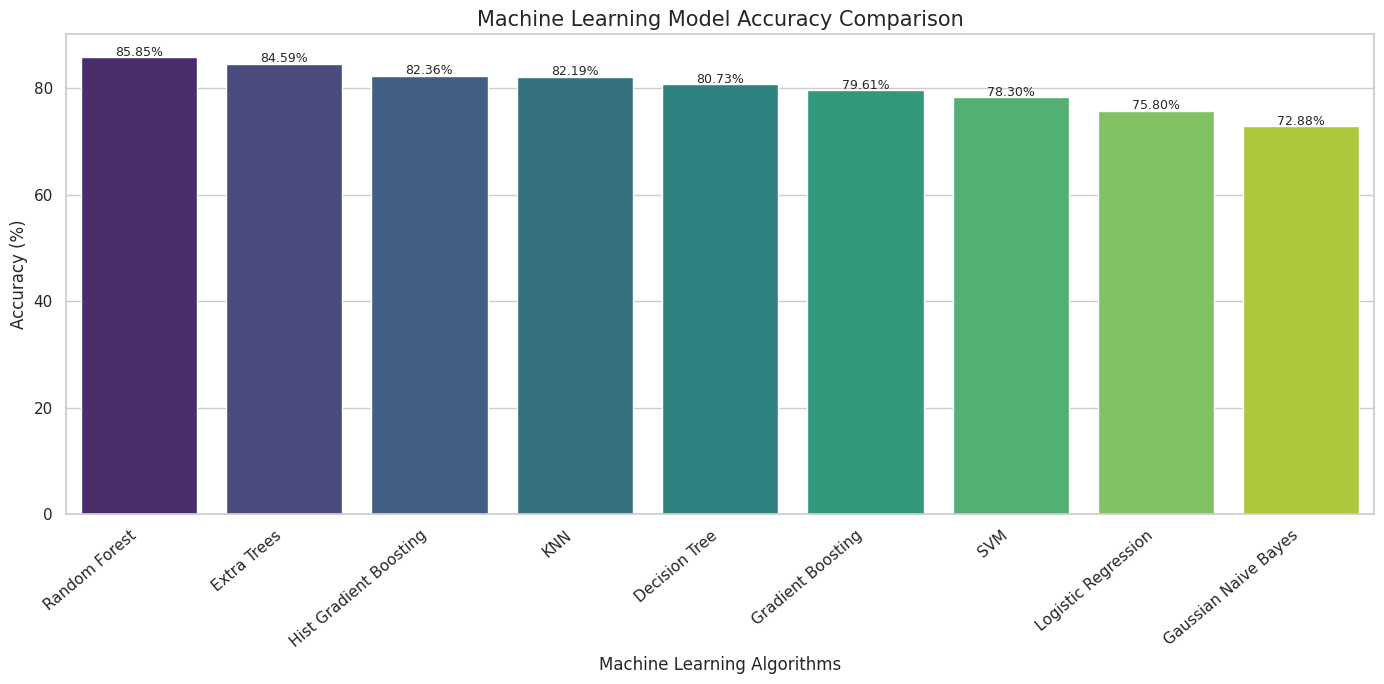

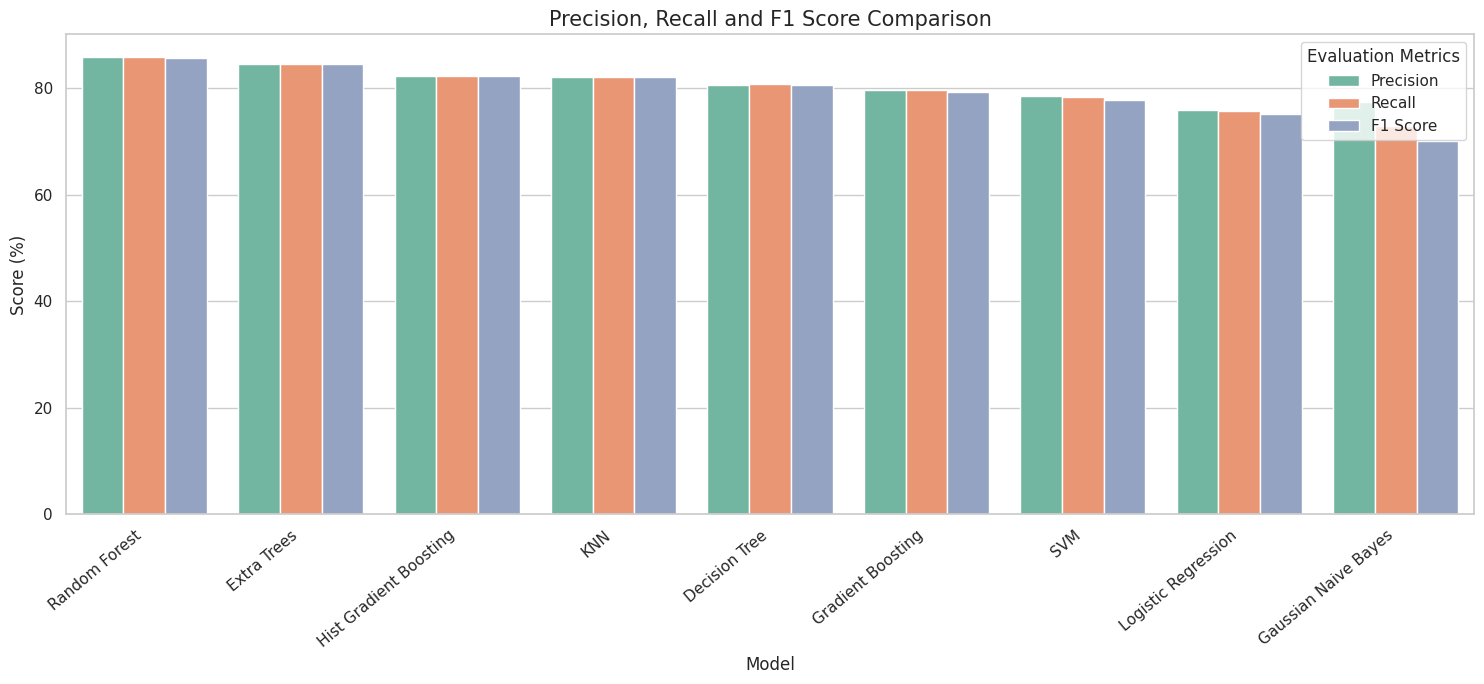

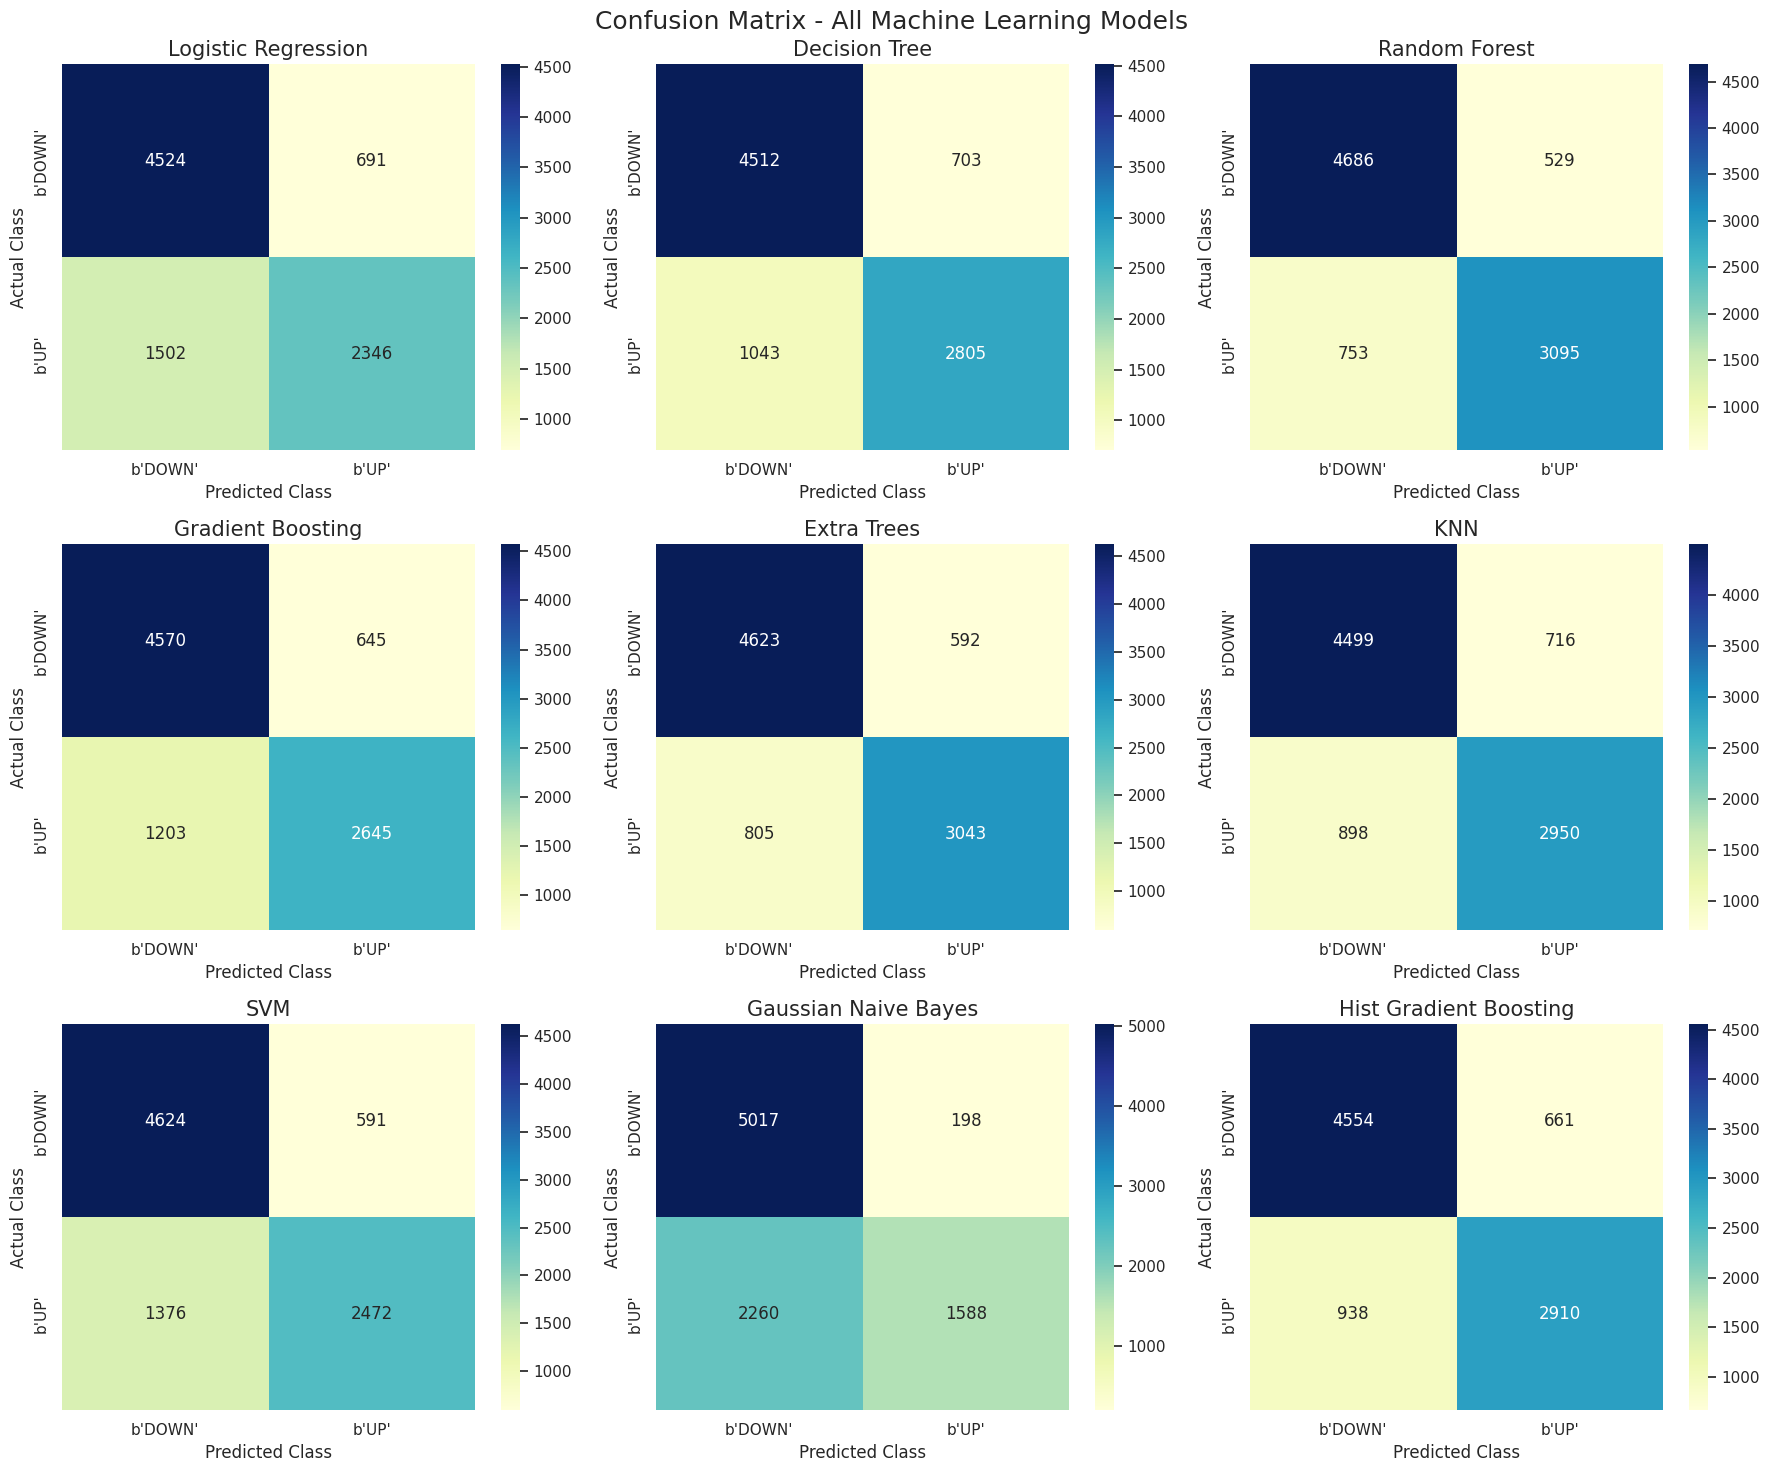

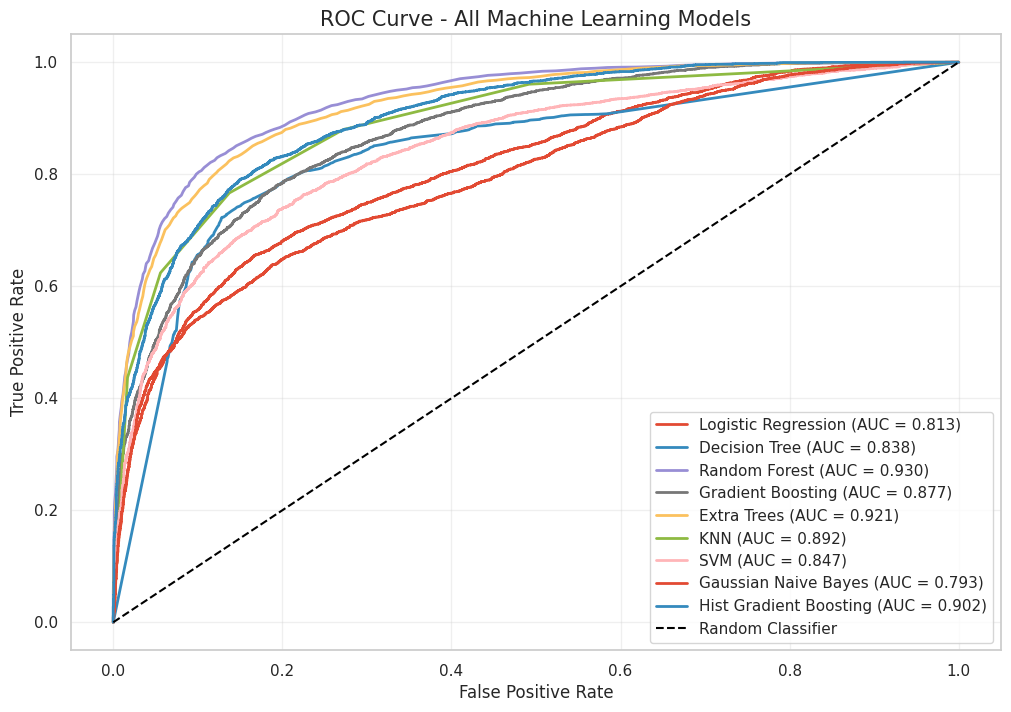


ROC AUC SCORE COMPARISON


,Model,ROC AUC
2,Random Forest,93.04
4,Extra Trees,92.14
8,Hist Gradient Boosting,90.16
5,KNN,89.24
3,Gradient Boosting,87.72
6,SVM,84.68
1,Decision Tree,83.85
0,Logistic Regression,81.28
7,Gaussian Naive Bayes,79.34


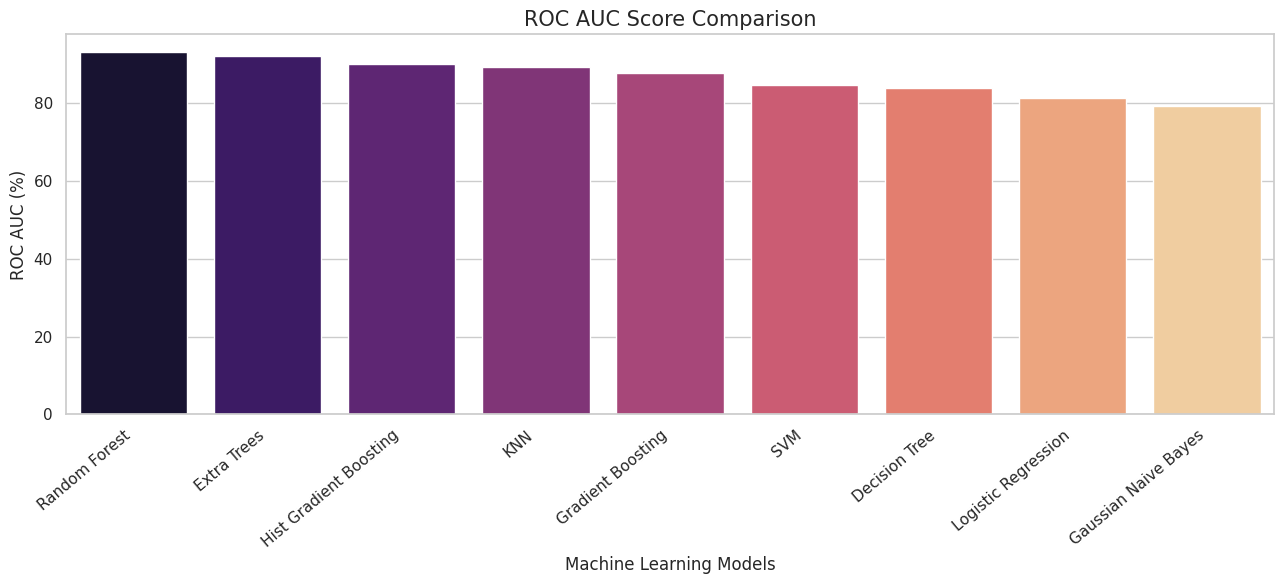


BEST MACHINE LEARNING MODEL
Best Model: Random Forest
Accuracy: 85.85 %
Precision: 85.84 %
Recall: 85.85 %
F1 Score: 85.79 %

Best ROC AUC Model: Random Forest
Best ROC AUC: 93.04 %

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

     b'DOWN'       0.86      0.90      0.88      5215
       b'UP'       0.85      0.80      0.83      3848

    accuracy                           0.86      9063
   macro avg       0.86      0.85      0.85      9063
weighted avg       0.86      0.86      0.86      9063


MACHINE LEARNING ANALYSIS COMPLETED SUCCESSFULLY!


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

sns.set_style('whitegrid')

print("DATASET SHAPE:", df.shape)

print("\nFIRST FIVE RECORDS")
display(df.head())

print("\nDATASET INFORMATION")
df.info()

# ================================================================
# 3. DATA PREPROCESSING
# ================================================================

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert date into datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Extract useful date features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_month'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

# Drop original date column
df.drop(columns=['date'], inplace=True)

# Remove rows where target is missing
df.dropna(subset=['class'], inplace=True)

# Define target
target = 'class'

X = df.drop(columns=[target])
y = df[target]

print("\nFEATURE COLUMNS:")
print(X.columns.tolist())

print("\nTARGET DISTRIBUTION:")
print(y.value_counts())

# ================================================================
# 4. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ================================================================

numeric_features = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNUMERICAL FEATURES:")
print(numeric_features)

print("\nCATEGORICAL FEATURES:")
print(categorical_features)

# ================================================================
# 5. TRAIN TEST SPLIT
# ================================================================

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y.astype(str))

print("\nTARGET LABEL ENCODING:")
for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

# 80% Training and 20% Testing
# Stratify preserves class proportions where possible.

class_counts = pd.Series(y_encoded).value_counts()
stratify_data = (
    y_encoded
    if class_counts.min() >= 2
    else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=stratify_data
)

print("\nTRAINING DATA:", X_train.shape)
print("TESTING DATA:", X_test.shape)

# ================================================================
# 6. LABEL ENCODING AND FEATURE SCALING
# ================================================================

# Fit imputers and encoders only on training data.

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_transformer, numeric_features),
        ('categorical', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPREPROCESSING COMPLETED")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

# ================================================================
# 7. MACHINE LEARNING ALGORITHMS
# ================================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    'Gaussian Naive Bayes': GaussianNB(),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

# ================================================================
# 8. TRAIN MODELS AND CALCULATE ACCURACY
# ================================================================

results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    try:

        # Train model
        model.fit(X_train_processed, y_train)

        # Predictions
        y_pred = model.predict(X_test_processed)

        # Probability predictions for ROC
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(X_test_processed)

        elif hasattr(model, 'decision_function'):
            decision_scores = model.decision_function(
                X_test_processed
            )

            if len(label_encoder.classes_) == 2:
                positive_score = decision_scores.ravel()
                y_prob = np.column_stack([
                    -positive_score,
                    positive_score
                ])
            else:
                y_prob = decision_scores

        else:
            y_prob = None

        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        # Store results
        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100
        })

        trained_models[name] = model
        predictions[name] = y_pred
        probabilities[name] = y_prob

        print("Accuracy  :", round(accuracy * 100, 2), "%")
        print("Precision :", round(precision * 100, 2), "%")
        print("Recall    :", round(recall * 100, 2), "%")
        print("F1 Score  :", round(f1 * 100, 2), "%")

        print("\nCLASSIFICATION REPORT:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        ))

    except Exception as e:
        print("MODEL FAILED:", name)
        print("ERROR:", e)

# ================================================================
# 9. MODEL PERFORMANCE COMPARISON
# ================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL PERFORMANCE")
display(results_df.round(2))

# ================================================================
# 10. ACCURACY COMPARISON
# ================================================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=40, ha='right')

for i, value in enumerate(results_df['Accuracy']):
    plt.text(i, value + 0.3, f'{value:.2f}%',
             ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ================================================================
# 11. PRECISION, RECALL AND F1 SCORE COMPARISON
# ================================================================

metrics_df = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=metrics_df,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title('Precision, Recall and F1 Score Comparison')
plt.ylabel('Score (%)')
plt.xticks(rotation=40, ha='right')
plt.legend(title='Evaluation Metrics')

plt.tight_layout()
plt.show()

# ================================================================
# 12. CONFUSION MATRICES FOR ALL MODELS
# ================================================================

class_names = label_encoder.classes_
n_models = len(trained_models)

fig, axes = plt.subplots(
    nrows=int(np.ceil(n_models / 3)),
    ncols=3,
    figsize=(18, 5 * int(np.ceil(n_models / 3)))
)

axes = np.array(axes).flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted Class')
    axes[i].set_ylabel('Actual Class')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Confusion Matrix - All Machine Learning Models',
             fontsize=18)

plt.tight_layout()
plt.show()

# ================================================================
# 13. ROC CURVE - BINARY CLASSIFICATION
# ================================================================

n_classes = len(class_names)

if n_classes == 2:

    plt.figure(figsize=(12, 8))

    for name, y_prob in probabilities.items():

        if y_prob is None:
            continue

        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'{name} (AUC = {roc_auc:.3f})'
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='black',
        label='Random Classifier'
    )

    plt.title('ROC Curve - All Machine Learning Models')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

# ================================================================
# 14. ROC CURVE - MULTICLASS CLASSIFICATION
# ================================================================

else:

    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(n_classes)
    )

    plt.figure(figsize=(12, 8))

    for name, y_prob in probabilities.items():

        if y_prob is None:
            continue

        # Macro ROC AUC
        try:
            macro_auc = roc_auc_score(
                y_test_binary,
                y_prob,
                average='macro',
                multi_class='ovr'
            )
        except ValueError:
            macro_auc = np.nan

        # Micro-average ROC
        fpr, tpr, _ = roc_curve(
            y_test_binary.ravel(),
            y_prob.ravel()
        )

        micro_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'{name} (Micro AUC = {micro_auc:.3f})'
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='black',
        label='Random Classifier'
    )

    plt.title('Multiclass ROC Curve - Model Comparison')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

# ================================================================
# 15. INDIVIDUAL ROC CURVES FOR EACH CLASS
# ================================================================

if n_classes > 2:

    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(n_classes)
    )

    for name, y_prob in probabilities.items():

        if y_prob is None:
            continue

        plt.figure(figsize=(10, 7))

        for i, class_name in enumerate(class_names):

            if len(np.unique(y_test_binary[:, i])) < 2:
                continue

            fpr, tpr, _ = roc_curve(
                y_test_binary[:, i],
                y_prob[:, i]
            )

            class_auc = auc(fpr, tpr)

            plt.plot(
                fpr,
                tpr,
                linewidth=2,
                label=f'{class_name} (AUC = {class_auc:.3f})'
            )

        plt.plot(
            [0, 1], [0, 1],
            '--',
            color='black'
        )

        plt.title(f'Individual Class ROC Curve - {name}')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend(loc='lower right')
        plt.grid(alpha=0.3)
        plt.show()

# ================================================================
# 16. ROC AUC SCORE COMPARISON
# ================================================================

roc_results = []

for name, y_prob in probabilities.items():

    if y_prob is None:
        continue

    try:

        if n_classes == 2:

            score = roc_auc_score(
                y_test,
                y_prob[:, 1]
            )

        else:

            score = roc_auc_score(
                y_test,
                y_prob,
                multi_class='ovr',
                average='macro'
            )

        roc_results.append({
            'Model': name,
            'ROC AUC': score * 100
        })

    except ValueError:
        print("ROC AUC unavailable for:", name)

roc_df = pd.DataFrame(roc_results)

if not roc_df.empty:

    roc_df = roc_df.sort_values(
        by='ROC AUC',
        ascending=False
    )

    print("\nROC AUC SCORE COMPARISON")
    display(roc_df.round(2))

    plt.figure(figsize=(13, 6))

    sns.barplot(
        data=roc_df,
        x='Model',
        y='ROC AUC',
        hue='Model',
        palette='magma',
        legend=False
    )

    plt.title('ROC AUC Score Comparison')
    plt.ylabel('ROC AUC (%)')
    plt.xlabel('Machine Learning Models')
    plt.xticks(rotation=40, ha='right')
    plt.tight_layout()
    plt.show()

# ================================================================
# 17. FINAL BEST MODEL
# ================================================================

if not results_df.empty:

    best_model_name = results_df.iloc[0]['Model']

    print("\n" + "=" * 60)
    print("BEST MACHINE LEARNING MODEL")
    print("=" * 60)

    print("Best Model:", best_model_name)

    print(
        "Accuracy:",
        round(results_df.iloc[0]['Accuracy'], 2),
        "%"
    )

    print(
        "Precision:",
        round(results_df.iloc[0]['Precision'], 2),
        "%"
    )

    print(
        "Recall:",
        round(results_df.iloc[0]['Recall'], 2),
        "%"
    )

    print(
        "F1 Score:",
        round(results_df.iloc[0]['F1 Score'], 2),
        "%"
    )

    if not roc_df.empty:

        best_roc = roc_df.sort_values(
            'ROC AUC',
            ascending=False
        ).iloc[0]

        print("\nBest ROC AUC Model:", best_roc['Model'])
        print("Best ROC AUC:", round(best_roc['ROC AUC'], 2), "%")

    print("\nFINAL CLASSIFICATION REPORT")

    print(
        classification_report(
            y_test,
            predictions[best_model_name],
            target_names=class_names,
            zero_division=0
        )
    )

print("\nMACHINE LEARNING ANALYSIS COMPLETED SUCCESSFULLY!")


## Thank you..pls upvote!!!!!